# Hvenær á að skerða? Vatnsafl og forgangsorka — SDP-líkan (hluti 4 og áfram)

Fartölvan er sjálfstæð: hún les `hydro_group_project_data.zip`, endurgerir hluta 1–2 (mánaðarinnrennsli, flokka og
líkindafylki) og leysir svo SDP-líkanið, sannprófar það og ber saman stefnur. Kóðinn er í einingunni
`curtail_sdp.py` (skrifuð í fyrsta reit) og tilraunirnar í reitunum þar á eftir.

**Keyrsla í Colab:** settu zip-skrána í `MyDrive/When_to_Curtail/` (sama slóð og í hluta 1) og keyrðu allt.
Heildartími er um 8–10 mín; óvissugreiningin (`B_URTOK`) og álagsprófið taka mestan tíma.

In [ ]:
# Uppsetning: Colab (Google Drive) eða staðbundin keyrsla
import os, sys, glob, zipfile
try:
    from google.colab import drive
    ZIP_PATH = "/content/hydro_group_project_data.zip"
    if not os.path.exists(ZIP_PATH) and not os.path.isdir("hydro_group_project_data"):
        drive.mount("/content/drive")
        ZIP_PATH = "/content/drive/MyDrive/hydro_group_project_data.zip"
except ImportError:
    ZIP_PATH = next(iter(glob.glob("**/hydro_group_project_data.zip", recursive=True)), "hydro_group_project_data.zip")

if not os.path.isdir("hydro_group_project_data") and os.path.exists(ZIP_PATH):
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(".")
MAPPA = os.environ.get("CURTAIL_DATA", "hydro_group_project_data/original_exports")
print("Gögn:", MAPPA, sorted(os.listdir(MAPPA)))

Gögn: hydro_group_project_data/original_exports ['Yfirlit raða.xlsx', 'expert_note_is.txt', 'fljotsdalsstod_framleidsla.csv', 'fljotsdalsstod_notad_vatn.csv', 'halslon_lonhaed.csv', 'halslon_natturulegt_innrennsli.csv', 'halslon_natturulegt_innrennsli_smoothed.csv', 'halslon_rennsli_um_yfirfall.csv', 'halslon_rummal.csv', 'jokulsargong_rennsli.csv']


In [ ]:
%%writefile curtail_sdp.py
"""
Hvenær á að skerða? Vatnsafl og forgangsorka (Verkefni 4, Aðgerðagreining 2).

Slembið kvikt bestunarlíkan (SDP) fyrir Fljótsdalsstöð:
  * gögn og mánaðarinnrennsli (hluti 1),
  * flokkun innrennslis og líkindafylki (hluti 2),
  * Bellman-lausn aftur á bak (hluti 3–4),
  * mat á stefnum: nákvæm upptalning allra innrennslisferla, dreifing á neti,
    keyrsla á sögulegum árum og klukkustundaendurspilun.

Allar einingar: rúmmál í Mm3 (= GL), afl í MW, rennsli í m3/s, líkanmánuður 730 klst.
"""
from __future__ import annotations

import os
from dataclasses import dataclass, field

import numpy as np
import pandas as pd
from scipy import stats

# ----------------------------------------------------------------------------
# 1. Fastar úr verkefnislýsingu
# ----------------------------------------------------------------------------
K = 690 / 144             # MW á hvert m3/s  (P = K q)
Q_MAX = 144.0             # m3/s
P_MAX = 575.0             # MW (ein 115 MW vél í viðhaldi)
KLST = 730                # klst. í líkanmánuði
C = KLST * 3600 / 1e6     # 2,628 Mm3 á hvert m3/s yfir líkanmánuð
V_MIN, V_MAX = 100.0, 2270.0
FAST, AUKA = 483.0, 54.0  # MW forgangsorka og skerðanleg orka
A_VATN = C / K            # Mm3 sem 1 MW notar í einn líkanmánuð (0,5484)
M_JAFN = 1 / A_VATN       # MW-mán á Mm3: vatn í lok árs jafnverðmætt og afhending núna (1,8234)
V1_GILDI = [1600, 1800, 1950]
THJALFUNARAR = list(range(2015, 2024))
PROFUNARAR = 2024
MAN = ["jan", "feb", "mar", "apr", "maí", "jún", "júl", "ágú", "sep", "okt", "nóv", "des"]
FLOKKAR = ["Lítið", "Miðlungs", "Mikið"]
GWH_A_MWMAN = KLST / 1000  # 1 MW í einn líkanmánuð = 0,73 GWh

RADIR = {
    "H": "halslon_natturulegt_innrennsli.csv",       # m3/s, hrátt (EKKI slétta röðin)
    "J": "jokulsargong_rennsli.csv",                 # m3/s
    "yfirfall": "halslon_rennsli_um_yfirfall.csv",   # m3/s
    "notad_vatn": "fljotsdalsstod_notad_vatn.csv",   # m3/s
    "afl": "fljotsdalsstod_framleidsla.csv",         # MW
    "rummal": "halslon_rummal.csv",                  # GL = Mm3
}


# ----------------------------------------------------------------------------
# 2. Gögn (hluti 1)
# ----------------------------------------------------------------------------
def lesa_rod(mappa: str, skra: str) -> pd.DataFrame:
    """Les eina klukkustundarröð: Latin-1, ';', tugakomma, '---' = vantar."""
    d = pd.read_csv(os.path.join(mappa, skra), sep=";", encoding="latin-1", dtype=str)
    d = d.loc[:, ~d.columns.str.startswith("Unnamed")]
    d = d.rename(columns={d.columns[0]: "dags", d.columns[1]: "klst", d.columns[2]: "txt"})
    d = d.dropna(subset=["dags"])
    d["timi"] = pd.to_datetime(d["dags"] + " " + d["klst"], format="%d.%m.%Y %H:%M:%S")
    txt = d["txt"].str.strip().replace({"---": None, "": None})
    d["gildi"] = pd.to_numeric(txt.str.replace(",", ".", regex=False), errors="coerce")
    flogg = [c for c in ("Valid", "Invalid", "Missing", "Quality", "Interpolation") if c in d.columns]
    return d[["timi", "gildi"] + flogg].reset_index(drop=True)


def lesa_gogn(mappa: str) -> dict:
    return {nafn: lesa_rod(mappa, skra) for nafn, skra in RADIR.items()}


def manadartafla(klst: dict) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Mánaðarrúmmál = meðaltal tiltækra klst.-gilda x klst. í almanaksmánuði x 0,0036 (Mm3)."""
    hlutar = []
    for nafn, d in klst.items():
        g = d.groupby([d["timi"].dt.year.rename("ar"), d["timi"].dt.month.rename("man")])["gildi"]
        hlutar.append(pd.DataFrame({f"{nafn}_medal": g.mean(), f"{nafn}_n": g.count()}))
    t = pd.concat(hlutar, axis=1)
    ar_, man_ = t.index.get_level_values("ar"), t.index.get_level_values("man")
    t["klst_i_man"] = pd.to_datetime(pd.DataFrame({"year": ar_, "month": man_, "day": 1})).dt.days_in_month.to_numpy() * 24
    for nafn in ("H", "J", "yfirfall", "notad_vatn"):
        t[f"{nafn}_Mm3"] = t[f"{nafn}_medal"] * t["klst_i_man"] * 0.0036
    t["innrennsli_Mm3"] = t["H_Mm3"] + t["J_Mm3"]
    t["framleidsla_GWh"] = t["afl_medal"] * t["klst_i_man"] / 1000
    t["nothaefur"] = (t["H_n"] >= 0.5 * t["klst_i_man"]) & (t["J_n"] >= 0.5 * t["klst_i_man"])
    t.loc[~t["nothaefur"], "innrennsli_Mm3"] = np.nan
    I = t["innrennsli_Mm3"].unstack("man")
    return t, I


# ----------------------------------------------------------------------------
# 3. Flokkun og líkindafylki (hluti 2)
# ----------------------------------------------------------------------------
def flokka(I_thj: pd.DataFrame) -> tuple[np.ndarray, pd.DataFrame]:
    """Mörk = 1/3 og 2/3 hlutfallsmörk hvers mánaðar (línuleg brúun); flokkur 0/1/2."""
    mork = np.array([np.quantile(I_thj[m].to_numpy(), [1 / 3, 2 / 3]) for m in range(1, 13)])
    flokkar = pd.DataFrame({m: np.searchsorted(mork[m - 1], I_thj[m].to_numpy(), side="right")
                            for m in range(1, 13)}, index=I_thj.index)
    return mork, flokkar


def flokkur(gildi, m: int, mork: np.ndarray):
    """Flokkur nýs gildis í almanaksmánuði m (1–12)."""
    return np.searchsorted(mork[m - 1], gildi, side="right")


def telja_umskipti(flokkar: pd.DataFrame) -> np.ndarray:
    """talningar[t, i, j]: fjöldi ára með flokk i í mánuði t-1 og flokk j í mánuði t (t=0: des árið á undan -> jan)."""
    n = np.zeros((12, 3, 3), dtype=int)
    ar = list(flokkar.index)
    for t in range(1, 12):
        for a in ar:
            n[t, flokkar.loc[a, t], flokkar.loc[a, t + 1]] += 1
    for a in ar:                       # des(a-1) -> jan(a), aðeins innan þjálfunaráranna
        if a - 1 in ar:
            n[0, flokkar.loc[a - 1, 12], flokkar.loc[a, 1]] += 1
    return n


def normal_flokkalikur(I_thj: pd.DataFrame, mork: np.ndarray, m: int) -> np.ndarray:
    """Flokkalíkur normaldreifingar sem er löguð að innrennsli mánaðar m (1–12) í þjálfunarárunum."""
    x = I_thj[m].to_numpy()
    mu, sd = x.mean(), x.std(ddof=1)
    F = stats.norm.cdf(mork[m - 1], mu, sd)
    return np.array([F[0], F[1] - F[0], 1 - F[1]])


def likindafylki(talningar: np.ndarray, I_thj: pd.DataFrame, mork: np.ndarray):
    """P[t, i, j] = Pr(C_t = j | C_{t-1} = i). Tóm röð -> normaldreifingarlíkur mánaðar t."""
    P = np.zeros((12, 3, 3))
    stadgenglar = []
    for t in range(12):
        for i in range(3):
            s = talningar[t, i].sum()
            if s > 0:
                P[t, i] = talningar[t, i] / s
            else:
                P[t, i] = normal_flokkalikur(I_thj, mork, t + 1)
                stadgenglar.append((t, i))
    return P, stadgenglar


def flokkamedaltol(I_thj: pd.DataFrame, flokkar: pd.DataFrame) -> np.ndarray:
    """Ibar[t, c] = meðalinnrennsli flokks c í mánuði t (Mm3)."""
    return np.array([[I_thj.loc[flokkar[t + 1] == c, t + 1].mean() for c in range(3)] for t in range(12)])


def des_dreifing(flokkar: pd.DataFrame) -> np.ndarray:
    """Reynsludreifing desemberflokks á þjálfunarárunum."""
    return np.bincount(flokkar[12].to_numpy(), minlength=3) / len(flokkar)


@dataclass
class Innrennslislikan:
    """Allt sem SDP-líkanið þarf um innrennsli."""
    mork: np.ndarray
    flokkar: pd.DataFrame
    talningar: np.ndarray
    P: np.ndarray
    Ibar: np.ndarray
    pi_des: np.ndarray
    stadgenglar: list = field(default_factory=list)


def smida_innrennslislikan(I_thj: pd.DataFrame) -> Innrennslislikan:
    mork, flokkar = flokka(I_thj)
    n = telja_umskipti(flokkar)
    P, st = likindafylki(n, I_thj, mork)
    return Innrennslislikan(mork, flokkar, n, P, flokkamedaltol(I_thj, flokkar), des_dreifing(flokkar), st)


# ----------------------------------------------------------------------------
# 4. Eðlisfræði eins mánaðar
# ----------------------------------------------------------------------------
def manudur(V, I):
    """Fyrir vatn í byrjun V og innrennsli I: (hámarksafl, afhent forgangsorka F, skortur D, hámark x).
    Forgangsorka fær vatnið fyrst; x <= 54 og x <= það sem eftir er af vatni og afli."""
    W = np.asarray(V, float) + np.asarray(I, float)
    B = np.maximum(0.0, W - V_MIN)
    Pbar = np.minimum(P_MAX, K * np.minimum(Q_MAX, B / C))
    F = np.minimum(FAST, Pbar)
    D = FAST - F
    xmax = np.clip(Pbar - F, 0.0, AUKA)
    return W, F, D, xmax


def lok_manadar(W, F, x):
    """Vatnsjafnvægi: V' = V + I - c q, yfirfall það sem fer yfir V_MAX."""
    Vp = W - C * (F + x) / K
    S = np.maximum(0.0, Vp - V_MAX)
    return np.minimum(Vp, V_MAX), S


# ----------------------------------------------------------------------------
# 5. SDP-líkanið
# ----------------------------------------------------------------------------
@dataclass
class Stillingar:
    V1: float = 1600.0          # upphafsstaða og markmið í lok árs
    M: float = 2 * M_JAFN       # refsing á hvern Mm3 sem vantar upp á V1 í lok árs (MW-mán/Mm3)
    lam: float = 0.0            # Lagrange-refsing fyrir ár með skorti á forgangsorku (MW-mán)
    mu: float = 10.0            # refsing á hvert MW-mán skorts á forgangsorku (forgangur líka milli mánaða)
    dV: float = 1.0             # netbil vatnsstöðu (Mm3)
    dx: float = 0.5             # netbil ákvörðunar (MW)
    jafntefli: float = 1e-3     # ef Q-gildi eru jöfn innan þessara marka (MW-mán) er stærra x valið


class SDP:
    """Bakvirk lausn Bellman-jöfnunnar á ástandinu (V, C, f):
    V = vatnsstaða í byrjun mánaðar, C = innrennslisflokkur mánaðarins (sést áður en ákveðið er),
    f = 1 ef skortur á forgangsorku hefur þegar orðið á árinu."""

    def __init__(self, il: Innrennslislikan, st: Stillingar, Ibar: np.ndarray | None = None):
        self.il, self.st = il, st
        self.Ibar = il.Ibar if Ibar is None else Ibar
        self.Vnet = np.round(np.arange(V_MIN, V_MAX + 1e-9, st.dV), 9)
        self.Xnet = np.round(np.arange(0.0, AUKA + 1e-9, st.dx), 9)
        nV = len(self.Vnet)
        self.J = np.zeros((12, 3, 2, nV))        # gildi eftir að innrennsli mánaðar sést
        self.G = np.zeros((12, 3, 2, nV))        # vænt framtíðargildi eftir ákvörðun (fall af V')
        self.stefna = np.zeros((12, 3, 2, nV))   # x*(t, c, f, V)

    # lokagildi: refsing fyrir að ná ekki V1 og Lagrange-refsing fyrir ár með skorti
    def lokagildi(self, V, f):
        return -self.st.M * np.maximum(0.0, self.st.V1 - V) - self.st.lam * f

    def _framhald(self, t, Vn, c, fn):
        """G_t(V', c, f') með línulegri brúun; c og fn eru fylki eða tölur."""
        out = np.empty_like(Vn)
        c = np.broadcast_to(c, Vn.shape[:1]); fn = np.broadcast_to(fn, Vn.shape[:1])
        for ci in range(3):
            for fi in range(2):
                r = (c == ci) & (fn == fi)
                if r.any():
                    out[r] = np.interp(Vn[r], self.Vnet, self.G[t, ci, fi])
        return out

    def akvarda(self, t, V, I, c, f, hluti=40000):
        """Besta x í mánuði t með einu Bellman-skrefi á raunverulegu ástandi (V, I, c, f).
        Skilar (x, Q-gildi, F, D). Ef jafnt er valið stærra x (afhent frekar en skert)."""
        V = np.atleast_1d(np.asarray(V, float)); I = np.broadcast_to(np.asarray(I, float), V.shape)
        c = np.broadcast_to(np.asarray(c), V.shape); f = np.broadcast_to(np.asarray(f), V.shape)
        if len(V) > hluti:     # skipt í búta til að spara minni
            bitar = [self.akvarda(t, V[i:i + hluti], I[i:i + hluti], c[i:i + hluti], f[i:i + hluti], hluti)
                     for i in range(0, len(V), hluti)]
            return tuple(np.concatenate([b[k] for b in bitar]) for k in range(4))
        W, F, D, xmax = manudur(V, I)
        fn = np.maximum(f, (D > 1e-9).astype(int))
        X = np.concatenate([np.broadcast_to(self.Xnet, (len(V), len(self.Xnet))), xmax[:, None]], axis=1)
        X = np.minimum(X, xmax[:, None])                         # óleyfileg gildi klippt að xmax
        Vn, _ = lok_manadar(W[:, None], F[:, None], X)
        n, a = X.shape
        cont = self._framhald(t, Vn.reshape(-1), np.repeat(c, a), np.repeat(fn, a)).reshape(n, a)
        Q = X - self.st.mu * D[:, None] + cont
        Qmax = Q.max(axis=1)
        valid = Q >= Qmax[:, None] - self.st.jafntefli
        x = np.where(valid, X, -1.0).max(axis=1)
        Qx = np.where(X == x[:, None], Q, -np.inf).max(axis=1)
        return x, Qx, F, D

    def leysa(self):
        nV = len(self.Vnet)
        for fi in range(2):
            self.G[11, :, fi] = self.lokagildi(self.Vnet, fi)
        for t in range(11, -1, -1):
            for ci in range(3):
                for fi in range(2):
                    x, Q, _, _ = self.akvarda(t, self.Vnet, self.Ibar[t, ci], np.full(nV, ci), np.full(nV, fi))
                    self.stefna[t, ci, fi], self.J[t, ci, fi] = x, Q
            if t > 0:
                # G_{t-1}(V', c_prev, f) = sum_c P_t(c_prev, c) J_t(V', c, f)
                self.G[t - 1] = np.einsum("ij,jfv->ifv", self.il.P[t], self.J[t])
        return self

    def U1(self, V, pi_des=None, f=0):
        """Vænt gildi í byrjun árs áður en janúarinnrennsli sést."""
        pi = self.il.pi_des if pi_des is None else np.asarray(pi_des, float)
        Jjan = np.array([np.interp(V, self.Vnet, self.J[0, c, f]) for c in range(3)])
        return float(pi @ self.il.P[0] @ Jjan)

    def stefnufall(self):
        return lambda t, V, I, c, f: self.akvarda(t, V, I, c, f)[0]


# ----------------------------------------------------------------------------
# 6. Samanburðarstefnur
# ----------------------------------------------------------------------------
def stefna_alltaf(t, V, I, c, f):
    """Afhenda 54 MW alltaf þegar vatn leyfir."""
    return manudur(V, I)[3]


def stefna_aldrei(t, V, I, c, f):
    """Aldrei afhenda skerðanlega orku."""
    return np.zeros_like(np.atleast_1d(np.asarray(V, float)))


class Vissujafngildi:
    """Vissujafngildisstefna (rúllandi áætlun með væntu innrennsli): í hverjum mánuði er leyst
    ákvarðanalaust vandamál þar sem framtíðarinnrennsli = skilyrt vænting miðað við núverandi flokk.
    Sama lokarefsing og sama skortsrefsing og í SDP (refsing lam á hvern skortsmánuð)."""

    def __init__(self, il: Innrennslislikan, st: Stillingar):
        self.il, self.st = il, st
        self.Vnet = np.round(np.arange(V_MIN, V_MAX + 1e-9, st.dV), 9)
        self.Xnet = np.round(np.arange(0.0, AUKA + 1e-9, st.dx), 9)
        self.H = np.zeros((12, 3, len(self.Vnet)))   # H[t, c](V'): gildi frá mánuði t+1 m.v. spá
        for t in range(12):
            for c in range(3):
                self.H[t, c] = self._akvardanalaust(t, c)

    def spa(self, t, c):
        """Vænt innrennsli mánaða t+1..11 miðað við C_t = c."""
        dreif = np.eye(3)[c]
        out = []
        for k in range(t + 1, 12):
            dreif = dreif @ self.il.P[k]
            out.append(float(dreif @ self.il.Ibar[k]))
        return out

    def _skref(self, Vnet, I, Hn):
        W, F, D, xmax = manudur(Vnet, I)
        X = np.minimum(np.concatenate([np.broadcast_to(self.Xnet, (len(Vnet), len(self.Xnet))), xmax[:, None]], 1), xmax[:, None])
        Vn, _ = lok_manadar(W[:, None], F[:, None], X)
        Q = X - self.st.mu * D[:, None] - self.st.lam * (D[:, None] > 1e-9) + np.interp(Vn, self.Vnet, Hn)
        return Q.max(1)

    def _akvardanalaust(self, t, c):
        Hn = -self.st.M * np.maximum(0.0, self.st.V1 - self.Vnet)
        for I in reversed(self.spa(t, c)):
            Hn = self._skref(self.Vnet, I, Hn)
        return Hn

    def __call__(self, t, V, I, c, f, hluti=40000):
        V = np.atleast_1d(np.asarray(V, float)); I = np.broadcast_to(np.asarray(I, float), V.shape)
        c = np.broadcast_to(np.asarray(c), V.shape)
        if len(V) > hluti:
            return np.concatenate([self(t, V[i:i + hluti], I[i:i + hluti], c[i:i + hluti], None, hluti)
                                   for i in range(0, len(V), hluti)])
        W, F, D, xmax = manudur(V, I)
        X = np.minimum(np.concatenate([np.broadcast_to(self.Xnet, (len(V), len(self.Xnet))), xmax[:, None]], 1), xmax[:, None])
        Vn, _ = lok_manadar(W[:, None], F[:, None], X)
        cont = np.empty_like(Vn)
        for ci in range(3):
            r = c == ci
            if r.any():
                cont[r] = np.interp(Vn[r], self.Vnet, self.H[t, ci])
        Q = X + cont
        Qmax = Q.max(1)
        return np.where(Q >= Qmax[:, None] - self.st.jafntefli, X, -1.0).max(1)


# ----------------------------------------------------------------------------
# 7. Mat: nákvæm upptalning allra flokkaferla líkansins
# ----------------------------------------------------------------------------
VIK_MARKMID = 1.0   # Mm3: lokastaða telst ná markmiði ef V13 >= V1 - 1 (námundun ákvarðananets)


def meta_slodir(stefna, il: Innrennslislikan, V1: float, pi_des=None, Ibar=None, P=None, geyma=False):
    """Telur upp alla flokkaferla (des, jan, ..., des) með jákvæðar líkur og keyrir stefnuna á þá.
    Innrennsli = flokkameðaltal. Skilar dict með væntigildum, mánaðarsniðum og (ef geyma) ferlum."""
    Ibar = il.Ibar if Ibar is None else Ibar
    P = il.P if P is None else P
    pi = il.pi_des if pi_des is None else np.asarray(pi_des, float)
    # mánuður 0: des-flokkur d -> jan-flokkur c
    d0 = np.repeat(np.arange(3), 3); c0 = np.tile(np.arange(3), 3)
    p = pi[d0] * P[0][d0, c0]
    keep = p > 0
    p, c = p[keep], c0[keep]
    n = len(p)
    V = np.full(n, float(V1)); f = np.zeros(n, int)
    sx = np.zeros(n); sD = np.zeros(n); sS = np.zeros(n); nD = np.zeros(n); Vmin = V.copy()
    saga = {"x": [], "V": [], "c": []} if geyma else None
    man = {k: np.zeros(12) for k in ("Ex", "Pskert", "ED", "ES", "EV", "Pskortur", "EI")}
    for t in range(12):
        I = Ibar[t, c]
        x = stefna(t, V, I, c, f)
        W, F, D, xmax = manudur(V, I)
        x = np.clip(x, 0.0, xmax)
        Vn, S = lok_manadar(W, F, x)
        man["Ex"][t] = p @ x; man["Pskert"][t] = p @ (x < AUKA - 1e-6); man["ED"][t] = p @ D
        man["ES"][t] = p @ S; man["EV"][t] = p @ Vn; man["Pskortur"][t] = p @ (D > 1e-9); man["EI"][t] = p @ I
        sx += x; sD += D; sS += S; nD += D > 1e-9
        f = np.maximum(f, (D > 1e-9).astype(int))
        V = Vn; Vmin = np.minimum(Vmin, V)
        if geyma:
            saga["x"].append(x); saga["V"].append(V); saga["c"].append(c)
        if t < 11:   # greinum í næsta flokk
            pr = P[t + 1][c]                       # (n, 3)
            idx, cn = np.nonzero(pr > 0)
            p = p[idx] * pr[idx, cn]; c = cn
            V, f, sx, sD, sS, nD, Vmin = V[idx], f[idx], sx[idx], sD[idx], sS[idx], nD[idx], Vmin[idx]
            if geyma:
                for k in saga:
                    saga[k] = [a[idx] for a in saga[k]]
    halli = np.maximum(0.0, V1 - V)
    res = {
        "p": p, "V13": V, "sum_x": sx, "sum_D": sD, "sum_S": sS, "f": f, "Vmin": Vmin, "halli": halli,
        "E_afhent_GWh": p @ sx * GWH_A_MWMAN,
        "E_skert_GWh": (12 * AUKA - p @ sx) * GWH_A_MWMAN,
        "areidanleiki": 1 - p @ f,
        "E_skortur_GWh": p @ sD * GWH_A_MWMAN,
        "E_yfirfall": p @ sS,
        "E_V13": p @ V,
        "P_V13_ge_V1": p @ (V >= V1 - VIK_MARKMID),
        "E_halli": p @ halli,
        "fjoldi_ferla": len(p),
        "man": man,
    }
    if geyma:
        res["saga"] = {k: np.array(v).T for k, v in saga.items()}
    return res


def meta_net(stefnutafla, il: Innrennslislikan, V1: float, Vnet, Ibar=None, P=None, pi_des=None):
    """Dreifir líkindamassa á netinu (V, c, f) með línulegri skiptingu milli netpunkta.
    stefnutafla[t, c, f, iV] = x á netinu. Hraðvirkt mat sem nota má innan leitar og óvissugreiningar."""
    Ibar = il.Ibar if Ibar is None else Ibar
    P = il.P if P is None else P
    pi = il.pi_des if pi_des is None else np.asarray(pi_des, float)
    nV, dV = len(Vnet), Vnet[1] - Vnet[0]
    massi = np.zeros((3, 2, nV))
    i1 = int(round((V1 - V_MIN) / dV))
    massi[:, 0, i1] = pi @ P[0]
    Ex = ED = ES = 0.0
    for t in range(12):
        nyr = np.zeros((3, 2, nV))
        for c in range(3):
            W, F, D, xmax = manudur(Vnet, Ibar[t, c])
            fn_skortur = (D > 1e-9).astype(int)
            for f in range(2):
                m = massi[c, f]
                if m.sum() <= 0:
                    continue
                x = np.minimum(stefnutafla[t, c, f], xmax)
                Vn, S = lok_manadar(W, F, x)
                Ex += m @ x; ED += m @ D; ES += m @ S
                pos = (Vn - V_MIN) / dV
                i0 = np.clip(np.floor(pos).astype(int), 0, nV - 1)
                w = np.where(i0 < nV - 1, pos - i0, 0.0)
                skipt = np.zeros((2, nV))
                fn = np.maximum(f, fn_skortur)
                for fi in range(2):
                    r = fn == fi
                    if r.any():
                        np.add.at(skipt[fi], i0[r], m[r] * (1 - w[r]))
                        np.add.at(skipt[fi], np.minimum(i0[r] + 1, nV - 1), m[r] * w[r])
                if t < 11:
                    nyr += P[t + 1][c][:, None, None] * skipt[None]
                else:
                    nyr[c] += skipt
        massi = nyr
    lok = massi.sum(axis=0)                      # (2, nV) eftir des
    halli = np.maximum(0.0, V1 - Vnet)
    return {
        "E_afhent_GWh": Ex * GWH_A_MWMAN, "E_skert_GWh": (12 * AUKA - Ex) * GWH_A_MWMAN,
        "E_skortur_GWh": ED * GWH_A_MWMAN, "E_yfirfall": ES,
        "areidanleiki": lok[0].sum(), "E_V13": lok.sum(0) @ Vnet,
        "P_V13_ge_V1": lok.sum(0) @ (Vnet >= V1 - VIK_MARKMID), "E_halli": lok.sum(0) @ halli,
    }


def finna_lam(il: Innrennslislikan, st: Stillingar, krafa=0.95, tol=1e-3, matsfall="slodir"):
    """Ytri leit (helmingun) að minnsta lam þannig að Pr(ár án skorts) >= krafa.
    Skilar (lam, SDP, mat, stada) þar sem stada er 'obindandi', 'bindandi' eða 'engin_stefna'."""
    def leysa(lam):
        s = Stillingar(**{**st.__dict__, "lam": lam})
        sdp = SDP(il, s).leysa()
        r = meta_slodir(sdp.stefnufall(), il, s.V1) if matsfall == "slodir" else meta_net(sdp.stefna, il, s.V1, sdp.Vnet)
        return sdp, r
    sdp, r = leysa(0.0)
    if r["areidanleiki"] >= krafa:
        return 0.0, sdp, r, "obindandi"
    r_aldrei = meta_slodir(stefna_aldrei, il, st.V1)
    if r_aldrei["areidanleiki"] < krafa:          # aldrei-afhenda er áreiðanlegasta stefnan
        return np.nan, None, r_aldrei, "engin_stefna"
    lo, hi = 0.0, 1.0
    while leysa(hi)[1]["areidanleiki"] < krafa:
        hi *= 4.0
    while hi - lo > tol * max(1.0, hi):
        mid = 0.5 * (lo + hi)
        if leysa(mid)[1]["areidanleiki"] >= krafa:
            hi = mid
        else:
            lo = mid
    sdp, r = leysa(hi)
    return hi, sdp, r, "bindandi"


def fullkomin_vitneskja(Ipaths, V1: float):
    """Efri mörk: besta ákvörðun þegar allt innrennsli ársins er þekkt fyrir fram (gildir þegar forgangsorka
    er aldrei í hættu). Fyrst er allt afhent; síðan er skert í síðustu mánuðum fyrst, aðeins það vatn sem
    skilar sér í lok árs (veldur ekki yfirfalli síðar), uns V13 = V1 eða ekki er hægt að gera betur.
    Rétt fyrir hvaða M > M_JAFN sem er."""
    n = Ipaths.shape[0]; Y = A_VATN * AUKA; firm = A_VATN * FAST
    V = np.full(n, float(V1)); Vend = np.zeros((n, 12))
    for t in range(12):
        Vp = V + Ipaths[:, t] - firm - Y
        if (Vp < V_MIN - 1e-9).any():
            raise ValueError("Forgangsorka í hættu: fullkomin vitneskja með einföldu reikniriti á ekki við")
        V = np.minimum(Vp, V_MAX); Vend[:, t] = V
    halli = np.maximum(0.0, V1 - Vend[:, 11]); y = np.zeros((n, 12))
    for t in range(11, -1, -1):
        rymi = (V_MAX - Vend[:, t:]).min(axis=1)
        yt = np.minimum(np.minimum(Y, halli), rymi)
        y[:, t] = yt; halli -= yt; Vend[:, t:] += yt[:, None]
    return AUKA - y / A_VATN, Vend, halli


def keyra_ar(stefna, I_ar, c_ar, V1: float):
    """Keyrir stefnu á eitt ár af raunverulegu innrennsli (12 gildi) og flokkum þess."""
    V, f = float(V1), 0
    lin = []
    for t in range(12):
        x = float(stefna(t, np.array([V]), np.array([I_ar[t]]), np.array([c_ar[t]]), np.array([f]))[0])
        W, F, D, xmax = manudur(V, I_ar[t])
        x = float(np.clip(x, 0.0, xmax))
        Vn, S = lok_manadar(W, F, x)
        lin.append(dict(man=MAN[t], I=I_ar[t], flokkur=FLOKKAR[int(c_ar[t])], V_byrjun=V, x=x, F=float(F),
                        D=float(D), yfirfall=float(S), V_lok=float(Vn)))
        f = max(f, int(D > 1e-9)); V = float(Vn)
    return pd.DataFrame(lin)


def samantekt_ars(df: pd.DataFrame, V1: float) -> dict:
    return {
        "afhent_GWh": df["x"].sum() * GWH_A_MWMAN,
        "skert_GWh": (12 * AUKA - df["x"].sum()) * GWH_A_MWMAN,
        "skertir_man": int((df["x"] < AUKA - 1e-6).sum()),
        "skortur_GWh": df["D"].sum() * GWH_A_MWMAN,
        "skortsmanudir": int((df["D"] > 1e-9).sum()),
        "yfirfall": df["yfirfall"].sum(),
        "V13": df["V_lok"].iloc[-1],
        "Vmin": df["V_lok"].min(),
        "halli": max(0.0, V1 - df["V_lok"].iloc[-1]),
    }

Writing curtail_sdp.py


In [ ]:
import json, time
import numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
import importlib, curtail_sdp as cs
importlib.reload(cs)
try:
    display
except NameError:            # keyrt sem skrifta
    display = print
INLINE = "ipykernel" in sys.modules
if not INLINE:
    matplotlib.use("Agg")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
UT, MYND = "results", "figures"
os.makedirs(UT, exist_ok=True); os.makedirs(MYND, exist_ok=True)
B_URTOK = 100        # fjöldi Dirichlet-úrtaka í óvissugreiningu (200 í skýrslutölum gefur sömu niðurstöðu)

LIT = dict(blar="#2a78d6", app="#eb6834", gr="#1baf7a", gulur="#eda100", fjol="#6250d6", raudur="#e34948",
           blek="#0b0b0b", blek2="#52514e", daufur="#898781", net="#e1e0d9", as_="#c3c2b7", hraedd="#d03b3b")
BLAR_RAMPI = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#2a78d6", "#1c5cab", "#104281", "#0d366b"]
V1_LITIR = dict(zip(cs.V1_GILDI, (LIT["blar"], LIT["app"], LIT["gr"])))
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 9.5, "axes.edgecolor": LIT["as_"],
    "axes.labelcolor": LIT["blek2"], "axes.titlesize": 10.5, "axes.titleweight": "bold", "axes.titlecolor": LIT["blek"],
    "xtick.color": LIT["blek2"], "ytick.color": LIT["blek2"], "axes.grid": True, "grid.color": LIT["net"],
    "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
    "lines.linewidth": 2.0,
})
MAN_STAFIR = [m[0].upper() for m in cs.MAN]
man = np.arange(1, 13)

def vista(fig, nafn):
    fig.savefig(os.path.join(MYND, nafn), bbox_inches="tight")
    plt.show() if INLINE else plt.close(fig)

def r(x, n=1):
    return None if x is None or (isinstance(x, float) and np.isnan(x)) else round(float(x), n)

NID = {}             # allar tölur, vistaðar í results/nidurstodur.json

## 1. Gögn og innrennslislíkan (endurgerð hluta 1–2)

In [ ]:
klst = cs.lesa_gogn(MAPPA)
t_man, I = cs.manadartafla(klst)
I_thj, I_2024 = I.loc[cs.THJALFUNARAR], I.loc[cs.PROFUNARAR]
il = cs.smida_innrennslislikan(I_thj)
c2024 = np.array([cs.flokkur(I_2024[m], m, il.mork) for m in range(1, 13)])
des2023 = int(il.flokkar.loc[2023, 12])

# Sannprófun á móti úttaki hluta 2 í fartölvu hópsins (flokkamörk og flokkameðaltöl)
mork_hopur = [(74.2, 95.3), (49.1, 77.0), (52.8, 61.5), (76.9, 137.0), (244.4, 324.7), (470.5, 715.6),
              (899.7, 1024.6), (791.5, 960.8), (505.7, 683.6), (203.2, 356.5), (129.1, 204.0), (80.5, 139.2)]
assert np.allclose(np.round(il.mork, 1), mork_hopur), "flokkamörk víkja frá hluta 2"
assert np.isclose(il.Ibar[0], [50.5, 87.9, 122.2], atol=0.05).all() and np.isclose(il.Ibar[6], [692.9, 955.0, 1169.9], atol=0.05).all()
assert cs.FLOKKAR[des2023] == "Lítið"
print("Hluti 1–2 endurgerður: flokkamörk, flokkameðaltöl og desemberflokkur 2023 stemma.")
print("Tómar raðir (normaldreifing notuð):", il.stadgenglar or "engar")

display(pd.DataFrame(il.Ibar, index=cs.MAN, columns=cs.FLOKKAR).round(1).T.rename_axis("Flokkameðaltöl (Mm³)"))
print("Flokkar 2024:", [cs.FLOKKAR[c] for c in c2024])
NID["gogn"] = {"Ibar": np.round(il.Ibar, 1).tolist(), "P": np.round(il.P, 3).tolist(), "talningar": il.talningar.tolist(),
               "mork": np.round(il.mork, 1).tolist(), "flokkar_2024": [cs.FLOKKAR[c] for c in c2024]}

# Mælingar sem notaðar eru til samanburðar
rum = klst["rummal"].set_index("timi")["gildi"]
afl = klst["afl"].set_index("timi")["gildi"]
jan1 = rum[(rum.index.month == 1) & (rum.index.day == 1) & (rum.index.hour == 0)]
maelt = pd.DataFrame({
    "rúmmál 1. jan": jan1.groupby(jan1.index.year).first(),
    "lægsta rúmmál": rum.groupby(rum.index.year).min(),
    "yfirfall (Mm³)": t_man["yfirfall_Mm3"].groupby(level="ar").sum(),
    "meðalafl (MW)": afl.groupby(afl.index.year).mean(),
    "innrennsli (Mm³)": I.sum(axis=1, min_count=12),
}).round(0)
display(maelt)
NID["maelt"] = maelt.to_dict(orient="index")

Hluti 1–2 endurgerður: flokkamörk, flokkameðaltöl og desemberflokkur 2023 stemma.
Tómar raðir (normaldreifing notuð): engar


,jan,feb,mar,apr,maí,jún,júl,ágú,sep,okt,nóv,des
Flokkameðaltöl (Mm³),,,,,,,,,,,,
Lítið,50.5,31.8,33.4,47.6,144.2,407.6,692.9,730.0,367.3,193.5,110.4,73.5
Miðlungs,87.9,58.4,59.8,95.7,296.3,602.9,955.0,858.4,569.0,257.9,151.7,97.8
Mikið,122.2,114.3,77.3,259.1,393.7,841.0,1169.9,1127.8,892.0,512.5,246.9,180.4


Flokkar 2024: ['Lítið', 'Lítið', 'Lítið', 'Lítið', 'Miðlungs', 'Lítið', 'Mikið', 'Mikið', 'Miðlungs', 'Lítið', 'Mikið', 'Mikið']


,rúmmál 1. jan,lægsta rúmmál,yfirfall (Mm³),meðalafl (MW),innrennsli (Mm³)
2015,1819.0,441.0,15.0,570.0,3956.0
2016,1851.0,483.0,666.0,576.0,4617.0
2017,1942.0,1010.0,925.0,579.0,4600.0
2018,1734.0,730.0,353.0,563.0,4218.0
2019,1838.0,1038.0,517.0,553.0,4093.0
2020,1746.0,500.0,191.0,550.0,3865.0
2021,1688.0,473.0,807.0,556.0,4481.0
2022,1628.0,612.0,264.0,578.0,4439.0
2023,1929.0,1023.0,827.0,591.0,4462.0
2024,1603.0,329.0,4.0,583.0,4194.0


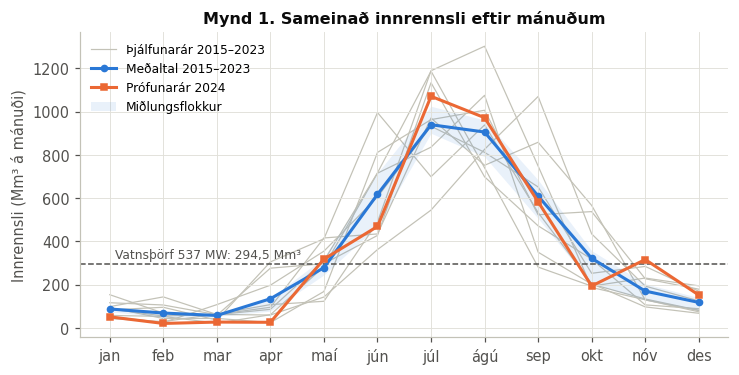

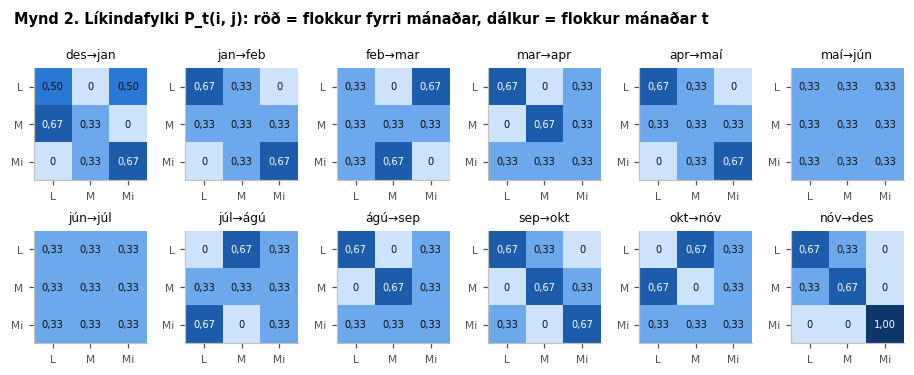

In [ ]:
# Mynd 1: árstíðasveifla og flokkamörk
fig, ax = plt.subplots(figsize=(7.6, 3.6))
for a in I_thj.index:
    ax.plot(man, I_thj.loc[a], color=LIT["as_"], lw=0.8, zorder=1)
ax.plot([], [], color=LIT["as_"], lw=0.8, label="Þjálfunarár 2015–2023")
ax.plot(man, I_thj.mean(), color=LIT["blar"], marker="o", ms=4, label="Meðaltal 2015–2023", zorder=3)
ax.plot(man, I_2024, color=LIT["app"], marker="s", ms=4, label="Prófunarár 2024", zorder=4)
ax.fill_between(man, il.mork[:, 0], il.mork[:, 1], color=LIT["blar"], alpha=0.10, lw=0, label="Miðlungsflokkur")
ax.axhline(cs.A_VATN * (cs.FAST + cs.AUKA), color=LIT["blek2"], lw=1, ls="--")
ax.text(1.1, cs.A_VATN * (cs.FAST + cs.AUKA) + 25, "Vatnsþörf 537 MW: 294,5 Mm³", color=LIT["blek2"], fontsize=8)
ax.set_xticks(man, cs.MAN); ax.set_ylabel("Innrennsli (Mm³ á mánuði)")
ax.set_title("Mynd 1. Sameinað innrennsli eftir mánuðum"); ax.legend(loc="upper left", fontsize=8)
vista(fig, "mynd1_innrennsli.png")

# Mynd 2: líkindafylkin
fig, axs = plt.subplots(2, 6, figsize=(8.4, 3.4))
for k, ax in enumerate(axs.flat):
    ax.imshow(il.P[k], cmap=matplotlib.colors.ListedColormap(BLAR_RAMPI), vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            v = il.P[k][i, j]
            ax.text(j, i, f"{v:.2f}".replace(".", ",") if v > 0 else "0", ha="center", va="center", fontsize=6.5,
                    color="white" if v > 0.55 else LIT["blek"])
    ax.set_xticks(range(3), ["L", "M", "Mi"], fontsize=7); ax.set_yticks(range(3), ["L", "M", "Mi"], fontsize=7)
    ax.grid(False); ax.set_title(f"{cs.MAN[k - 1] if k else 'des'}→{cs.MAN[k]}", fontsize=8, fontweight="normal")
fig.suptitle("Mynd 2. Líkindafylki P_t(i, j): röð = flokkur fyrri mánaðar, dálkur = flokkur mánaðar t",
             fontsize=9.5, fontweight="bold", x=0.02, ha="left")
fig.tight_layout()
vista(fig, "mynd2_likindafylki.png")

## 2. SDP-lausn fyrir V₁ = 1600, 1800 og 1950

Aðferð hópsins: ástand (V, flokkur, f), lokarefsing M = 2M* á hvern Mm³ undir V₁, refsing μ = 10 á MW-mán skorts
og Lagrange-refsing λ á ár með skorti, fundin með helmingunarleit (`finna_lam`) svo Pr(ár án skorts) ≥ 95%.

In [ ]:
grunnur = {}
for V1 in cs.V1_GILDI:
    st = cs.Stillingar(V1=V1)
    lam, sdp, _, stada = cs.finna_lam(il, st)          # ytri leit að λ
    st = sdp.st
    rs = cs.meta_slodir(sdp.stefnufall(), il, V1, geyma=True)
    Ip = np.array([il.Ibar[t, rs["saga"]["c"][:, t]] for t in range(12)]).T
    grunnur[V1] = dict(st=st, sdp=sdp, rs=rs, Ip=Ip, lam=lam, stada=stada)
    print(f"V1 = {V1}: λ* = {lam} ({stada}), U1 = {sdp.U1(V1):.2f} MW-mán, áreiðanleiki = {rs['areidanleiki']:.4f}, "
          f"ferlar = {rs['fjoldi_ferla']}")
NID["lam"] = {V1: {"lam": g["lam"], "stada": g["stada"]} for V1, g in grunnur.items()}

V1 = 1600: λ* = 0.0 (obindandi), U1 = 638.43 MW-mán, áreiðanleiki = 1.0000, ferlar = 66528
V1 = 1800: λ* = 0.0 (obindandi), U1 = 638.43 MW-mán, áreiðanleiki = 1.0000, ferlar = 66528
V1 = 1950: λ* = 0.0 (obindandi), U1 = 483.27 MW-mán, áreiðanleiki = 1.0000, ferlar = 66528


## 3. Sannprófun

In [ ]:
sann = {}
# (a) nákvæm trjáleit án nets á sep–des á móti Bellman á neti með sömu aðgerðum {0; 13,5; 27; 40,5; 54}
for V1 in (1600, 1950):
    st = cs.Stillingar(V1=V1, dx=13.5); sdp_g = cs.SDP(il, st).leysa(); acts = np.arange(0, 54.01, 13.5)
    def tre(t, V, c):
        W, F, D, xmax = cs.manudur(V, il.Ibar[t, c]); best = -1e18
        for x in sorted(set(list(np.minimum(acts, xmax)) + [float(xmax)])):
            Vn, S = cs.lok_manadar(W, F, x)
            val = x - st.mu * float(D)
            if t == 11:
                val += -st.M * max(0.0, st.V1 - float(Vn))
            else:
                val += sum(il.P[t + 1][c, j] * tre(t + 1, float(Vn), j) for j in range(3) if il.P[t + 1][c, j] > 0)
            best = max(best, val)
        return best
    frav = [abs(tre(8, float(V), c) - float(np.interp(V, sdp_g.Vnet, sdp_g.J[8, c, 0])))
            for V in np.linspace(900, 2270, 12) for c in range(3)]
    sann[f"tre_{V1}"] = {"max": r(max(frav), 3), "medal": r(np.mean(frav), 4)}
# (b) vatnsjafnvægi á öllum ferlum, (c) bakvirkt gildi = framvirkt mat, (d) net á móti ferlum
for V1, g in grunnur.items():
    rs, st, sdp = g["rs"], g["st"], g["sdp"]
    jafnv = V1 + g["Ip"].sum(1) - cs.A_VATN * (12 * cs.FAST - rs["sum_D"] + rs["sum_x"]) - rs["sum_S"] - rs["V13"]
    rn = cs.meta_net(sdp.stefna, il, V1, sdp.Vnet)
    sann[f"grunnur_{V1}"] = {
        "U1": r(sdp.U1(V1), 3),
        "markgildi_ferlar": r(rs["p"] @ (rs["sum_x"] - st.mu * rs["sum_D"] - st.M * rs["halli"] - st.lam * rs["f"]), 3),
        "jafnvaegi_max_frav": float(np.abs(jafnv).max()), "summa_likinda": r(rs["p"].sum(), 12),
        "net_vs_ferlar_afhent": [r(rn["E_afhent_GWh"], 3), r(rs["E_afhent_GWh"], 3)],
        "net_vs_ferlar_halli": [r(rn["E_halli"], 3), r(rs["E_halli"], 3)],
        "laegsta_V": r(rs["Vmin"].min(), 0)}
# (e) einhalli stefnunnar í V
sdp = grunnur[1600]["sdp"]; x = sdp.stefna[:, :, 0]
sann["einhalli_brot"] = [int((np.diff(x, axis=2) < -0.5).sum()), int(x[..., 1:].size)]
# (f) netþéttleiki
konv = []
for dV in (0.5, 1.0, 2.0, 5.0):
    for dx in (0.25, 0.5, 1.0, 2.0):
        for V1 in (1600, 1950):
            s = cs.Stillingar(V1=V1, dV=dV, dx=dx); t0 = time.time(); sd = cs.SDP(il, s).leysa(); tl = time.time() - t0
            rr = cs.meta_slodir(sd.stefnufall(), il, V1)
            konv.append(dict(dV=dV, dx=dx, V1=V1, U1=r(sd.U1(V1), 2), afhent_GWh=r(rr["E_afhent_GWh"], 2),
                             E_halli=r(rr["E_halli"], 2), timi_s=r(tl, 2)))
konv = pd.DataFrame(konv)
sann["netthettleiki_spann_U1"] = {V1: r(d.U1.max() - d.U1.min(), 3) for V1, d in konv.groupby("V1")}
NID["sannprofun"] = sann
print(json.dumps(sann, indent=1, ensure_ascii=False))
display(konv.pivot_table(index=["dV", "dx"], columns="V1", values=["U1", "afhent_GWh"]))

{
 "tre_1600": {
  "max": 0.349,
  "medal": 0.0204
 },
 "tre_1950": {
  "max": 0.09,
  "medal": 0.0055
 },
 "grunnur_1600": {
  "U1": 638.428,
  "markgildi_ferlar": 638.431,
  "jafnvaegi_max_frav": 1.5916157281026244e-12,
  "summa_likinda": 1.0,
  "net_vs_ferlar_afhent": [
   469.102,
   469.1
  ],
  "net_vs_ferlar_halli": [
   1.145,
   1.144
  ],
  "laegsta_V": 435.0
 },
 "grunnur_1800": {
  "U1": 638.428,
  "markgildi_ferlar": 638.431,
  "jafnvaegi_max_frav": 1.3642420526593924e-12,
  "summa_likinda": 1.0,
  "net_vs_ferlar_afhent": [
   469.102,
   469.1
  ],
  "net_vs_ferlar_halli": [
   1.145,
   1.144
  ],
  "laegsta_V": 635.0
 },
 "grunnur_1950": {
  "U1": 483.267,
  "markgildi_ferlar": 483.265,
  "jafnvaegi_max_frav": 1.3642420526593924e-12,
  "summa_likinda": 1.0,
  "net_vs_ferlar_afhent": [
   398.301,
   398.304
  ],
  "net_vs_ferlar_halli": [
   17.098,
   17.1
  ],
  "laegsta_V": 785.0
 },
 "einhalli_brot": [
  46,
  78120
 ],
 "netthettleiki_spann_U1": {
  "1600": 0.03,
 

U1         afhent_GWh        
V1          1600    1950       1600    1950
dV  dx                                     
0.5 0.25  638.43  483.27     469.10  398.29
    0.50  638.43  483.27     469.10  398.30
    1.00  638.43  483.26     469.10  398.28
    2.00  638.43  483.24     469.10  398.28
1.0 0.25  638.43  483.27     469.11  398.29
    0.50  638.43  483.27     469.10  398.30
    1.00  638.43  483.26     469.11  398.28
    2.00  638.42  483.23     469.11  398.28
2.0 0.25  638.42  483.27     469.09  398.29
    0.50  638.42  483.27     469.09  398.30
    1.00  638.42  483.26     469.09  398.28
    2.00  638.42  483.21     469.11  398.28
5.0 0.25  638.41  483.24     469.08  398.29
    0.50  638.41  483.24     469.08  398.30
    1.00  638.40  483.22     469.11  398.28
    2.00  638.40  483.16     469.11  398.28

## 4. Samanburður stefna (allir innrennslisferlar líkansins, nákvæmar líkur)

In [ ]:
def malikvardar(res, V1, nafn, M):
    out = {"stefna": nafn, "V1": V1,
           "tekjur_%": r(100 * res["E_afhent_GWh"] / (12 * cs.AUKA * cs.GWH_A_MWMAN), 1),
           "afhent_GWh": r(res["E_afhent_GWh"], 1), "skert_GWh": r(res["E_skert_GWh"], 1),
           "áreiðanleiki": r(res["areidanleiki"], 4), "skortur_GWh": r(res["E_skortur_GWh"], 2),
           "yfirfall_Mm3": r(res["E_yfirfall"], 0), "E_V13": r(res["E_V13"], 0),
           "P(V13≥V1)": r(res["P_V13_ge_V1"], 3), "E_halli_Mm3": r(res["E_halli"], 1)}
    if "sum_x" in res:
        out["markgildi"] = r(res["p"] @ (res["sum_x"] - M * res["halli"]), 1)
    return out

samanb, snid = [], {}
for V1, g in grunnur.items():
    st, rs, p = g["st"], g["rs"], g["rs"]["p"]
    ce = cs.Vissujafngildi(il, st)
    res = {"Alltaf afhenda": cs.meta_slodir(cs.stefna_alltaf, il, V1),
           "Aldrei afhenda": cs.meta_slodir(cs.stefna_aldrei, il, V1),
           "Vissujafngildi": cs.meta_slodir(ce, il, V1), "SDP": rs}
    for nafn, rr in res.items():
        samanb.append(malikvardar(rr, V1, nafn, st.M))
    # Fullkomin vitneskja (efri mörk) á sömu ferlum
    xpi, Vend, hpi = cs.fullkomin_vitneskja(g["Ip"], V1)
    Vb = np.concatenate([np.full((len(p), 1), float(V1)), Vend[:, :11]], axis=1)
    pi = {"E_afhent_GWh": p @ xpi.sum(1) * cs.GWH_A_MWMAN, "E_skert_GWh": (12 * cs.AUKA - p @ xpi.sum(1)) * cs.GWH_A_MWMAN,
          "areidanleiki": 1.0, "E_skortur_GWh": 0.0, "E_V13": p @ Vend[:, 11], "E_halli": p @ hpi,
          "P_V13_ge_V1": p @ (Vend[:, 11] >= V1 - cs.VIK_MARKMID),
          "E_yfirfall": p @ np.maximum(0, Vb + g["Ip"] - cs.A_VATN * (cs.FAST + xpi) - cs.V_MAX).sum(1)}
    m = malikvardar(pi, V1, "Fullkomin vitneskja", st.M); m["markgildi"] = r(p @ (xpi.sum(1) - st.M * hpi), 1)
    samanb.append(m)
    Vs, xs = rs["saga"]["V"], rs["saga"]["x"]
    def hlutf(a, q):
        o = np.argsort(a); return a[o][np.searchsorted(np.cumsum(p[o]), q)]
    snid[V1] = {"Ex": rs["man"]["Ex"], "Ex_CE": res["Vissujafngildi"]["man"]["Ex"], "Ex_PI": p @ xpi,
                "Pskert": rs["man"]["Pskert"], "ES": rs["man"]["ES"],
                "V_hlutf": {q: np.array([hlutf(Vs[:, t], q) for t in range(12)]) for q in (0.05, 0.25, 0.5, 0.75, 0.95)},
                "P_aldrei_skert": r(p @ (rs["sum_x"] >= 12 * cs.AUKA - 1e-6), 3),
                "P_skert_jan_jul": r(p @ (xs[:, :7] < cs.AUKA - 1e-6).any(1), 3),
                "P_skert_agu_des": r(p @ (xs[:, 7:] < cs.AUKA - 1e-6).any(1), 3),
                "P_fullt_sep": r(p @ (Vs[:, 8] >= cs.V_MAX - 1e-6), 3), "P_yfirfall": r(p @ (rs["sum_S"] > 1e-6), 3)}
samanb = pd.DataFrame(samanb)
samanb.to_csv(os.path.join(UT, "samanburdur_stefna.csv"), index=False)
display(samanb)
display(pd.DataFrame({V1: {k: v for k, v in s.items() if k.startswith("P_")} for V1, s in snid.items()}))
display(pd.DataFrame({V1: np.round(cs.AUKA - s["Ex"], 2) for V1, s in snid.items()}, index=cs.MAN).T.rename_axis("Vænt skerðing (MW)"))
NID["samanburdur"] = samanb.to_dict(orient="records")
NID["snid"] = {V1: {k: (np.round(v, 2).tolist() if isinstance(v, np.ndarray) else
                       ({str(q): np.round(a, 0).tolist() for q, a in v.items()} if isinstance(v, dict) else v))
                    for k, v in s.items()} for V1, s in snid.items()}

,stefna,V1,tekjur_%,afhent_GWh,skert_GWh,áreiðanleiki,skortur_GWh,yfirfall_Mm3,E_V13,P(V13≥V1),E_halli_Mm3,markgildi
0,Alltaf afhenda,1600,100.0,473.0,-0.0,1.0,0.0,475.0,1894.0,0.966,3.7,634.4
1,Aldrei afhenda,1600,0.0,0.0,473.0,1.0,0.0,727.0,1997.0,1.000,0.0,0.0
2,Vissujafngildi,1600,99.3,469.7,3.3,1.0,0.0,475.0,1897.0,0.977,1.5,638.2
3,SDP,1600,99.2,469.1,3.9,1.0,0.0,475.0,1897.0,0.985,1.1,638.4
4,Fullkomin vitneskja,1600,99.0,468.1,5.0,1.0,0.0,475.0,1898.0,1.000,0.0,641.2
5,Alltaf afhenda,1800,100.0,473.0,-0.0,1.0,0.0,654.0,1915.0,0.966,3.7,634.4
6,Aldrei afhenda,1800,0.0,0.0,473.0,1.0,0.0,924.0,2001.0,1.000,0.0,0.0
7,Vissujafngildi,1800,99.3,469.7,3.3,1.0,0.0,654.0,1917.0,0.977,1.5,638.2
8,SDP,1800,99.2,469.1,3.9,1.0,0.0,654.0,1918.0,0.985,1.1,638.4
9,Fullkomin vitneskja,1800,99.0,468.1,5.0,1.0,0.0,654.0,1919.0,1.000,0.0,641.2


,1600,1800,1950
P_aldrei_skert,0.954,0.954,0.111
P_skert_jan_jul,0.000,0.000,0.000
P_skert_agu_des,0.046,0.046,0.889
P_fullt_sep,0.820,0.933,0.979
P_yfirfall,0.842,0.941,0.982


,jan,feb,mar,apr,maí,jún,júl,ágú,sep,okt,nóv,des
Vænt skerðing (MW),,,,,,,,,,,,
1600,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.24,0.75,1.53,1.43,1.45
1800,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.24,0.75,1.53,1.43,1.45
1950,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.24,0.51,36.00,33.01,32.61


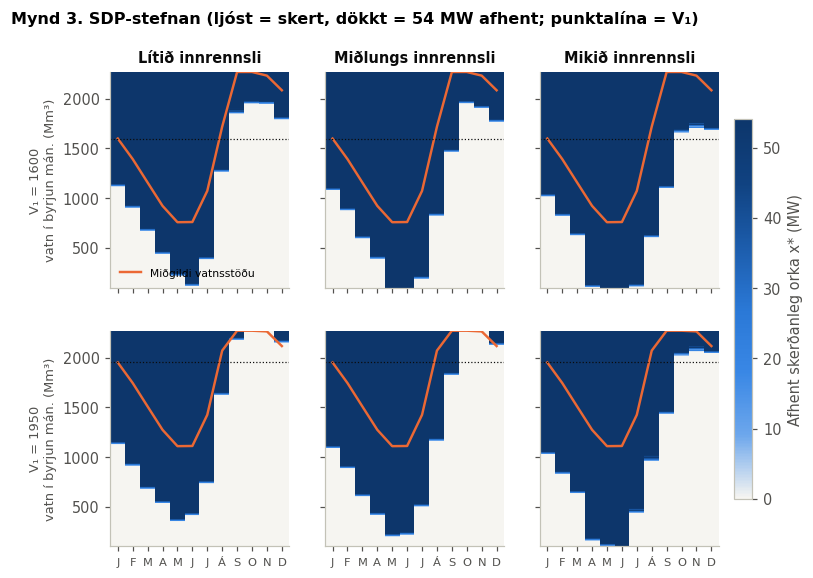

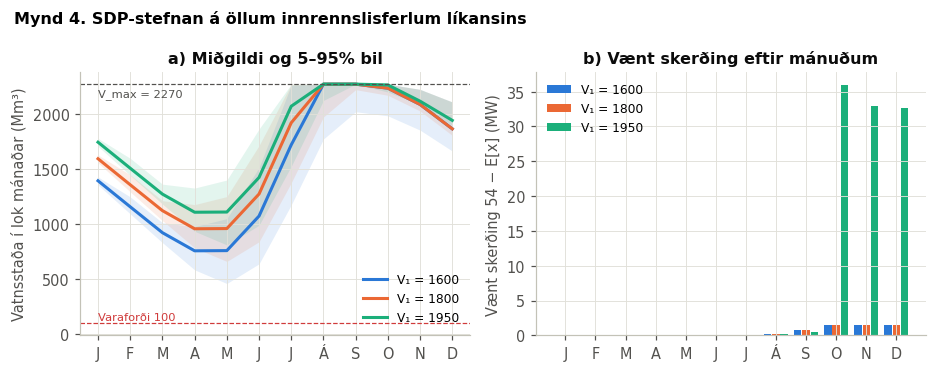

In [ ]:
# Mynd 3: stefnukort x*(mánuður, V) eftir innrennslisflokki
fig, axs = plt.subplots(2, 3, figsize=(8.6, 5.6), sharex=True, sharey=True)
cmap = matplotlib.colors.LinearSegmentedColormap.from_list("blar", ["#f6f5f1"] + BLAR_RAMPI[2:])
for row, V1 in enumerate((1600, 1950)):
    sdp = grunnur[V1]["sdp"]
    V_byrjun_mid = np.r_[V1, snid[V1]["V_hlutf"][0.5][:11]]
    for c in range(3):
        ax = axs[row, c]
        im = ax.imshow(sdp.stefna[:, c, 0].T, origin="lower", aspect="auto", cmap=cmap, vmin=0, vmax=54,
                       extent=[0.5, 12.5, cs.V_MIN, cs.V_MAX], interpolation="nearest")
        ax.grid(False)
        ax.plot(man, V_byrjun_mid, color=LIT["app"], lw=1.6, label="Miðgildi vatnsstöðu")
        ax.axhline(V1, color=LIT["blek"], lw=0.8, ls=":")
        ax.set_xticks(man, MAN_STAFIR, fontsize=7.5)
        if row == 0:
            ax.set_title(f"{cs.FLOKKAR[c]} innrennsli", fontsize=9.5)
        if c == 0:
            ax.set_ylabel(f"V₁ = {V1}\nvatn í byrjun mán. (Mm³)", fontsize=8.5)
axs[0, 0].legend(loc="lower left", fontsize=7)
cb = fig.colorbar(im, ax=axs, shrink=0.8, pad=0.02); cb.set_label("Afhent skerðanleg orka x* (MW)")
fig.suptitle("Mynd 3. SDP-stefnan (ljóst = skert, dökkt = 54 MW afhent; punktalína = V₁)", fontsize=10.5,
             fontweight="bold", x=0.02, ha="left")
vista(fig, "mynd3_stefnukort.png")

# Mynd 4: dreifing vatnsstöðu og vænt skerðing eftir mánuðum
fig, axs = plt.subplots(1, 2, figsize=(8.6, 3.4))
ax = axs[0]
for V1 in cs.V1_GILDI:
    h = snid[V1]["V_hlutf"]
    ax.fill_between(man, h[0.05], h[0.95], color=V1_LITIR[V1], alpha=0.12, lw=0)
    ax.plot(man, h[0.5], color=V1_LITIR[V1], label=f"V₁ = {V1}")
ax.axhline(cs.V_MAX, color=LIT["blek2"], lw=0.8, ls="--"); ax.text(1, cs.V_MAX - 110, "V_max = 2270", fontsize=7.5, color=LIT["blek2"])
ax.axhline(cs.V_MIN, color=LIT["hraedd"], lw=0.8, ls="--"); ax.text(1, cs.V_MIN + 30, "Varaforði 100", fontsize=7.5, color=LIT["hraedd"])
ax.set_xticks(man, MAN_STAFIR); ax.set_ylabel("Vatnsstaða í lok mánaðar (Mm³)")
ax.set_title("a) Miðgildi og 5–95% bil"); ax.legend(fontsize=8, loc="lower right")
ax = axs[1]
for k, V1 in enumerate(cs.V1_GILDI):
    ax.bar(man + (k - 1) * 0.27, cs.AUKA - snid[V1]["Ex"], width=0.24, color=V1_LITIR[V1], label=f"V₁ = {V1}")
ax.set_xticks(man, MAN_STAFIR); ax.set_ylabel("Vænt skerðing 54 − E[x] (MW)")
ax.set_title("b) Vænt skerðing eftir mánuðum"); ax.legend(fontsize=8, loc="upper left")
fig.suptitle("Mynd 4. SDP-stefnan á öllum innrennslisferlum líkansins", fontsize=10.5, fontweight="bold", x=0.02, ha="left")
fig.tight_layout()
vista(fig, "mynd4_ferlar.png")

## 5. Næmni fyrir verðmæti vatns í lok árs (M)

skert_GWh             P_V13_ge_V1               skert_jan_jul_MWman            
V1                     1600  1800  1950        1600   1800   1950                1600  1800  1950
M_sinnum_Mstjarna                                                                                
1.01                    2.5   2.5  48.2       0.977  0.977  0.444                 0.0   0.0   0.0
1.25                    2.5   2.5  48.3       0.977  0.977  0.444                 0.0   0.0   0.0
1.50                    2.5   2.5  48.3       0.977  0.977  0.444                 0.0   0.0   0.0
2.00                    3.9   3.9  74.7       0.985  0.985  0.444                 0.0   0.0   0.0
3.00                    4.9   4.9  75.3       0.988  0.988  0.444                 0.0   0.0   0.0
5.00                    6.0   6.0  76.3       0.990  0.990  0.444                 0.7   0.7   0.6
10.00                   8.6   8.6  77.9       0.993  0.993  0.444                 4.7   4.7   3.0
30.00                  11.8  11.8  79.8       0.995  0.995  0.444                 9.7   9.7   5.8
100.00                 22.4  22.4  87.7       0.998  0.998  0.444                25.7  25.7  17.1

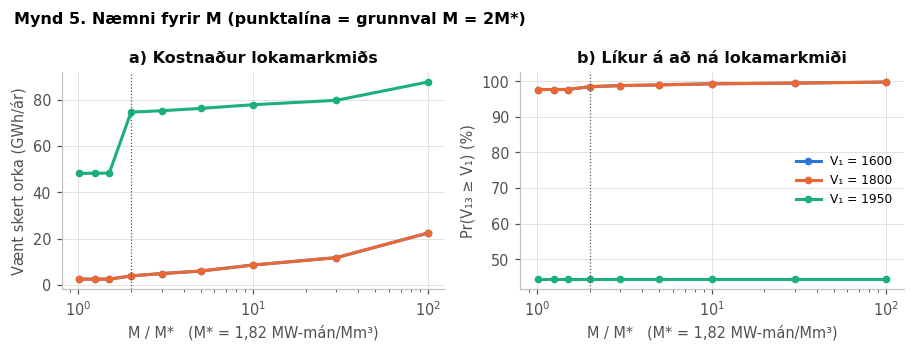

In [ ]:
nM = []
for V1 in cs.V1_GILDI:
    for k in (1.01, 1.25, 1.5, 2, 3, 5, 10, 30, 100):
        s = cs.Stillingar(V1=V1, M=k * cs.M_JAFN); sd = cs.SDP(il, s).leysa(); rr = cs.meta_slodir(sd.stefnufall(), il, V1)
        nM.append(dict(V1=V1, M_sinnum_Mstjarna=k, skert_GWh=r(rr["E_skert_GWh"], 1), P_V13_ge_V1=r(rr["P_V13_ge_V1"], 3),
                       E_halli=r(rr["E_halli"], 2), skert_jan_jul_MWman=r((cs.AUKA - rr["man"]["Ex"][:7]).sum(), 1)))
nM = pd.DataFrame(nM); nM.to_csv(os.path.join(UT, "naemni_M.csv"), index=False)
display(nM.pivot(index="M_sinnum_Mstjarna", columns="V1", values=["skert_GWh", "P_V13_ge_V1", "skert_jan_jul_MWman"]))
NID["naemni_M"] = nM.to_dict(orient="records")

fig, axs = plt.subplots(1, 2, figsize=(8.4, 3.2))
for V1 in cs.V1_GILDI:
    d = nM[nM.V1 == V1]
    axs[0].plot(d.M_sinnum_Mstjarna, d.skert_GWh, color=V1_LITIR[V1], marker="o", ms=4, label=f"V₁ = {V1}")
    axs[1].plot(d.M_sinnum_Mstjarna, 100 * d.P_V13_ge_V1, color=V1_LITIR[V1], marker="o", ms=4, label=f"V₁ = {V1}")
for ax in axs:
    ax.set_xscale("log"); ax.set_xlabel("M / M*   (M* = 1,82 MW-mán/Mm³)"); ax.axvline(2, color=LIT["blek2"], lw=0.8, ls=":")
axs[0].set_ylabel("Vænt skert orka (GWh/ár)"); axs[0].set_title("a) Kostnaður lokamarkmiðs")
axs[1].set_ylabel("Pr(V₁₃ ≥ V₁) (%)"); axs[1].set_title("b) Líkur á að ná lokamarkmiði"); axs[1].legend(fontsize=8)
fig.suptitle("Mynd 5. Næmni fyrir M (punktalína = grunnval M = 2M*)", fontsize=10.5, fontweight="bold", x=0.02, ha="left")
fig.tight_layout()
vista(fig, "mynd5_naemni_M.png")

## 6. Söguleg ár (innan úrtaks) og prófunarárið 2024 (utan mats)

In [ ]:
sogu = []
for V1, g in grunnur.items():
    pols = {"Alltaf afhenda": cs.stefna_alltaf, "Vissujafngildi": cs.Vissujafngildi(il, g["st"]), "SDP": g["sdp"].stefnufall()}
    for ar in range(2015, 2025):
        Iar = I.loc[ar].to_numpy(); car = np.array([cs.flokkur(Iar[m], m + 1, il.mork) for m in range(12)])
        for nafn, pol in pols.items():
            df = cs.keyra_ar(pol, Iar, car, V1)
            sogu.append(dict(V1=V1, ar=ar, stefna=nafn, **{k: r(v, 1) for k, v in cs.samantekt_ars(df, V1).items()},
                             manudir="".join("·" if v < 0.01 else ("▒" if v < cs.AUKA - 1e-6 else "█") for v in df["x"])))
sogu = pd.DataFrame(sogu); sogu.to_csv(os.path.join(UT, "soguleg_ar.csv"), index=False)
display(sogu[sogu.stefna == "SDP"].pivot(index="ar", columns="V1", values=["skert_GWh", "manudir", "V13", "yfirfall"]))
print("█ = 54 MW afhent, ▒ = skert að hluta, · = skert að fullu")
NID["soguleg"] = sogu.to_dict(orient="records")

# Prófunarárið 2024 frá V1 = 1600: grunnval og varkárari M; ex ante m.v. desemberflokk 2023 (Lítið)
Iar = I_2024.to_numpy(); prof = {}
for k in (2, 10, 100):
    s = cs.Stillingar(V1=1600, M=k * cs.M_JAFN); sd = cs.SDP(il, s).leysa()
    prof[k] = cs.keyra_ar(sd.stefnufall(), Iar, c2024, 1600)
    prof[k].round(1).to_csv(os.path.join(UT, f"prof2024_M{k}.csv"), index=False)
    ea = cs.meta_slodir(sd.stefnufall(), il, 1600, pi_des=np.eye(3)[des2023])
    NID[f"prof2024_M{k}"] = {"samantekt": {kk: r(v, 1) for kk, v in cs.samantekt_ars(prof[k], 1600).items()},
                             "ex_ante": malikvardar(ea, 1600, "ex ante", s.M), "x": prof[k]["x"].round(1).tolist()}
display(prof[2].round(1))
display(pd.DataFrame({f"M = {k}M*": NID[f"prof2024_M{k}"]["samantekt"] for k in prof}))
print("Ex ante 2024 (grunnval):", NID["prof2024_M2"]["ex_ante"])
rum24 = rum[rum.index.year == 2024].resample("D").mean()
afl24 = afl[afl.index.year == 2024].resample("MS").mean()
NID["maelt_2024"] = {"afl_man": np.round(afl24.to_numpy(), 0).tolist(),
                     "rum_lok_man": [r(rum[(rum.index.year == 2024) & (rum.index.month == m)].dropna().iloc[-1], 0) for m in man]}
print("Mælt rúmmál í lok mánaðar 2024:", NID["maelt_2024"]["rum_lok_man"])
print("Raunveruleg framleiðsla 2024 (MW):", NID["maelt_2024"]["afl_man"])

skert_GWh                    manudir                                 V13                 yfirfall               
V1        1600  1800   1950          1600          1800          1950    1600    1800    1950     1600   1800    1950
ar                                                                                                                   
2015      39.4  39.4   24.5  ███████·████  ███████·████  ███████▒████  1997.8  1997.8  1997.8     54.0  254.0   392.8
2016       0.0   0.0    0.0  ████████████  ████████████  ████████████  2086.3  2086.3  2086.3    596.6  796.6   946.6
2017       0.0   0.0   78.8  ████████████  ████████████  ██████████··  1889.3  1889.3  1948.5    776.7  976.7  1126.7
2018       0.0   0.0   57.7  ████████████  ████████████  ████████▒·██  1989.2  1989.2  2032.6    294.6  494.6   644.6
2019       0.0   0.0   78.8  ████████████  ████████████  ██████████··  1875.0  1875.0  1934.2    283.4  483.4   633.4
2020       0.0   0.0  118.3  ████████████  ████████████  █████████···  1802.2  1802.2  1891.0    128.5  328.5   478.5
2021       0.0  32.1  118.3  ████████████  ███████████▒  █████████···  1775.9  1800.1  1864.8    771.0  971.0  1121.0
2022       0.0   0.0   39.4  ████████████  ████████████  █████████·██  2091.0  2091.0  2120.6    413.5  613.5   763.5
2023       0.0  57.3  118.3  ████████████  ██████████▒·  █████████···  1753.9  1797.0  1842.8    773.6  973.6  1123.6
2024       0.0   0.0   39.4  ████████████  ████████████  █████████·██  2046.7  2046.7  2076.3    212.8  412.8   562.8

█ = 54 MW afhent, ▒ = skert að hluta, · = skert að fullu


,man,I,flokkur,V_byrjun,x,F,D,yfirfall,V_lok
0,jan,50.5,Lítið,1600.0,54.0,483.0,0.0,0.0,1355.9
1,feb,20.0,Lítið,1355.9,54.0,483.0,0.0,0.0,1081.4
2,mar,26.3,Lítið,1081.4,54.0,483.0,0.0,0.0,813.2
3,apr,25.3,Lítið,813.2,54.0,483.0,0.0,0.0,544.0
4,maí,317.5,Miðlungs,544.0,54.0,483.0,0.0,0.0,567.0
5,jún,468.6,Lítið,567.0,54.0,483.0,0.0,0.0,741.1
6,júl,1070.7,Mikið,741.1,54.0,483.0,0.0,0.0,1517.3
7,ágú,971.8,Mikið,1517.3,54.0,483.0,0.0,0.0,2194.6
8,sep,582.7,Miðlungs,2194.6,54.0,483.0,0.0,212.8,2270.0
9,okt,193.3,Lítið,2270.0,54.0,483.0,0.0,0.0,2168.8


,M = 2M*,M = 10M*,M = 100M*
afhent_GWh,473.0,473.0,419.4
skert_GWh,0.0,0.0,53.7
skertir_man,0.0,0.0,2.0
skortur_GWh,0.0,0.0,0.0
skortsmanudir,0.0,0.0,0.0
yfirfall,212.8,212.8,253.1
V13,2046.7,2046.7,2046.7
Vmin,544.0,544.0,584.3
halli,0.0,0.0,0.0


Ex ante 2024 (grunnval): {'stefna': 'ex ante', 'V1': 1600, 'tekjur_%': 99.1, 'afhent_GWh': 469.0, 'skert_GWh': 4.1, 'áreiðanleiki': 1.0, 'skortur_GWh': 0.0, 'yfirfall_Mm3': 475.0, 'E_V13': 1897.0, 'P(V13≥V1)': 0.985, 'E_halli_Mm3': 1.2, 'markgildi': 638.1}
Mælt rúmmál í lok mánaðar 2024: [1304.0, 994.0, 676.0, 380.0, 378.0, 529.0, 1291.0, 1942.0, 2187.0, 2056.0, 2030.0, 1811.0]
Raunveruleg framleiðsla 2024 (MW): [591.0, 600.0, 578.0, 548.0, 535.0, 559.0, 548.0, 586.0, 628.0, 580.0, 621.0, 626.0]


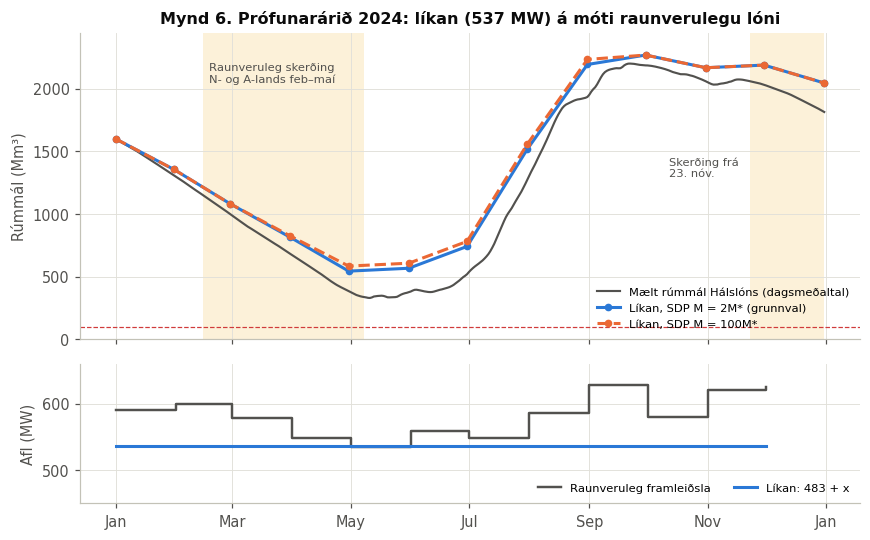

In [ ]:
# Mynd 6: 2024 – líkan á móti mældu rúmmáli og framleiðslu
fig, axs = plt.subplots(2, 1, figsize=(8.0, 5.0), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
manlok = pd.to_datetime([f"2024-{m:02d}-01" for m in man]) + pd.offsets.MonthEnd(0)
ax = axs[0]
ax.plot(rum24.index, rum24.to_numpy(), color=LIT["blek2"], lw=1.4, label="Mælt rúmmál Hálslóns (dagsmeðaltal)")
for k, lit, ls in ((2, LIT["blar"], "-"), (100, LIT["app"], "--")):
    ax.plot([pd.Timestamp("2024-01-01")] + list(manlok), [1600] + list(prof[k]["V_lok"]), color=lit, ls=ls, marker="o", ms=4,
            label=f"Líkan, SDP M = {k}M*" + (" (grunnval)" if k == 2 else ""))
ax.axhline(cs.V_MIN, color=LIT["hraedd"], lw=0.8, ls="--")
for a, b in (("2024-02-15", "2024-05-08"), ("2024-11-23", "2024-12-31")):
    ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color=LIT["gulur"], alpha=0.15, lw=0)
ax.text(pd.Timestamp("2024-02-18"), 2050, "Raunveruleg skerðing\nN- og A-lands feb–maí", fontsize=7.5, color=LIT["blek2"])
ax.text(pd.Timestamp("2024-10-12"), 1300, "Skerðing frá\n23. nóv.", fontsize=7.5, color=LIT["blek2"])
ax.set_ylim(0, 2450); ax.set_ylabel("Rúmmál (Mm³)"); ax.legend(fontsize=7.5, loc="lower right")
ax.set_title("Mynd 6. Prófunarárið 2024: líkan (537 MW) á móti raunverulegu lóni")
ax = axs[1]
ax.step(afl24.index, afl24.to_numpy(), where="post", color=LIT["blek2"], lw=1.6, label="Raunveruleg framleiðsla")
ax.step(afl24.index, cs.FAST + prof[2]["x"].to_numpy(), where="post", color=LIT["blar"], label="Líkan: 483 + x")
ax.set_ylabel("Afl (MW)"); ax.set_ylim(450, 660); ax.legend(fontsize=7.5, loc="lower right", ncol=2)
ax.xaxis.set_major_formatter(matplotlib.dates.DateFormatter("%b"))
fig.tight_layout()
vista(fig, "mynd6_2024.png")

## 7. Klukkustundaendurspilun 2024: nægir mánaðarlegt vatnsjafnvægi?

,klst í mán,"líkan, lok mán","klst, lok mán","klst, lægst í mán",dýfa undir lok mán
1,744,1356.0,1350.0,1350.0,0.0
2,696,1081.0,1089.0,1089.0,0.0
3,744,813.0,816.0,816.0,0.0
4,720,544.0,550.0,550.0,0.0
5,744,567.0,568.0,497.0,53.0
6,720,741.0,746.0,568.0,0.0
7,744,1517.0,1516.0,747.0,0.0
8,744,2195.0,2188.0,1518.0,0.0
9,720,2270.0,2267.0,2189.0,0.0
10,744,2169.0,2160.0,2160.0,0.0


Lægsta klst-staða 497 Mm³ (2024-05-11 09:00:00); lægsta mánaðarstaða líkans 544 Mm³
Klst. 2024 með neikvætt reiknað innrennsli: 1292 af 8784


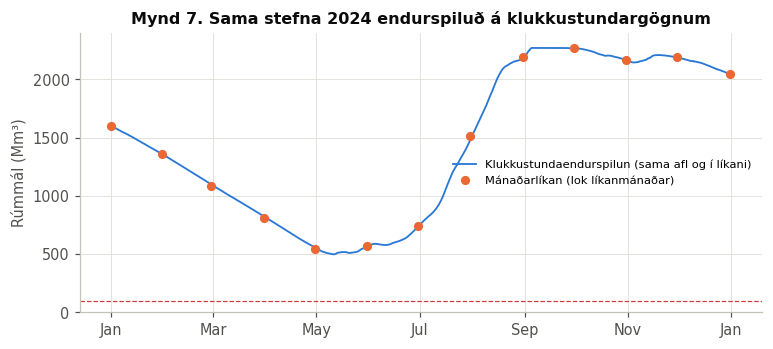

In [ ]:
H = klst["H"].set_index("timi")["gildi"]; J = klst["J"].set_index("timi")["gildi"]
k24 = pd.DataFrame({"H": H, "J": J}); k24 = k24[k24.index.year == 2024].copy()
for col in ("H", "J"):          # eyður: meðaltal tiltækra gilda í sama mánuði (sama regla og í mánaðarrúmmáli)
    k24[col] = k24[col].fillna(k24.groupby(k24.index.month)[col].transform("mean"))
inn = ((k24["H"] + k24["J"]) * 0.0036).to_numpy()                       # Mm3 á klst
q = ((prof[2]["F"] + prof[2]["x"]).to_numpy() / cs.K)[k24.index.month - 1]  # sama afl og í líkani, allar almanaksklst.
Vk = np.empty(len(k24)); v = 1600.0
for i in range(len(k24)):
    v = min(cs.V_MAX, v + inn[i] - 0.0036 * q[i]); Vk[i] = v
k24["V"] = Vk
gr = k24["V"].groupby(k24.index.month)
klst_tafla = pd.DataFrame({"klst í mán": k24.groupby(k24.index.month).size(), "líkan, lok mán": prof[2]["V_lok"].to_numpy(),
                           "klst, lok mán": gr.last(), "klst, lægst í mán": gr.min()}, index=man).round(0)
klst_tafla["dýfa undir lok mán"] = (np.minimum(np.r_[1600, klst_tafla["klst, lok mán"].to_numpy()[:-1]],
                                    klst_tafla["klst, lok mán"]) - klst_tafla["klst, lægst í mán"]).clip(lower=0).round(0)
display(klst_tafla)
print(f"Lægsta klst-staða {Vk.min():.0f} Mm³ ({k24.index[np.argmin(Vk)]}); lægsta mánaðarstaða líkans {prof[2]['V_lok'].min():.0f} Mm³")
print(f"Klst. 2024 með neikvætt reiknað innrennsli: {int(((k24['H'] + k24['J']) < 0).sum())} af {len(k24)}")
NID["klst2024"] = {"tafla": klst_tafla.to_dict(orient="index"), "lagmark": [r(Vk.min(), 0), str(k24.index[np.argmin(Vk)])]}

fig, ax = plt.subplots(figsize=(8.0, 3.3))
ax.plot(k24.index, Vk, color=LIT["blar"], lw=1.2, label="Klukkustundaendurspilun (sama afl og í líkani)")
ax.plot([pd.Timestamp("2024-01-01")] + list(manlok), [1600] + list(prof[2]["V_lok"]), color=LIT["app"], lw=0, marker="o", ms=5,
        label="Mánaðarlíkan (lok líkanmánaðar)")
ax.axhline(cs.V_MIN, color=LIT["hraedd"], lw=0.8, ls="--"); ax.set_ylim(0, 2400); ax.set_ylabel("Rúmmál (Mm³)")
ax.xaxis.set_major_formatter(matplotlib.dates.DateFormatter("%b"))
ax.set_title("Mynd 7. Sama stefna 2024 endurspiluð á klukkustundargögnum"); ax.legend(fontsize=7.5, loc="center right")
vista(fig, "mynd7_klst2024.png")

## 8. Óvissa í líkindafylkjum

{
 "1600": {
  "fryst": {
   "E_afhent_GWh": [
    461.354,
    469.391,
    471.826
   ],
   "P_V13_ge_V1": [
    0.947,
    0.986,
    0.996
   ],
   "E_halli": [
    0.262,
    1.108,
    6.642
   ],
   "areidanleiki": [
    1.0,
    1.0,
    1.0
   ]
  },
  "endurleyst": {
   "E_afhent_GWh": [
    460.166,
    469.871,
    472.018
   ],
   "P_V13_ge_V1": [
    0.95,
    0.985,
    0.995
   ],
   "E_halli": [
    0.308,
    1.211,
    6.241
   ],
   "areidanleiki": [
    1.0,
    1.0,
    1.0
   ]
  },
  "eftirsja_MWman_5_50_95": [
   0.03,
   0.27,
   0.95
  ],
  "oahadir_manudir_fryst": {
   "stefna": "fryst",
   "V1": 1600,
   "tekjur_%": 98.8,
   "afhent_GWh": 467.5,
   "skert_GWh": 5.5,
   "áreiðanleiki": 1.0,
   "skortur_GWh": 0.0,
   "yfirfall_Mm3": 477.0,
   "E_V13": 1897.0,
   "P(V13≥V1)": 0.981,
   "E_halli_Mm3": 1.9,
   "markgildi": 633.5
  },
  "arsinnrennsli_kedja": {
   "medal": 4303.0,
   "sd": 463.0,
   "min": 3186.0,
   "max": 5920.0,
   "P_lt_3534": 0.0344
  }
 },


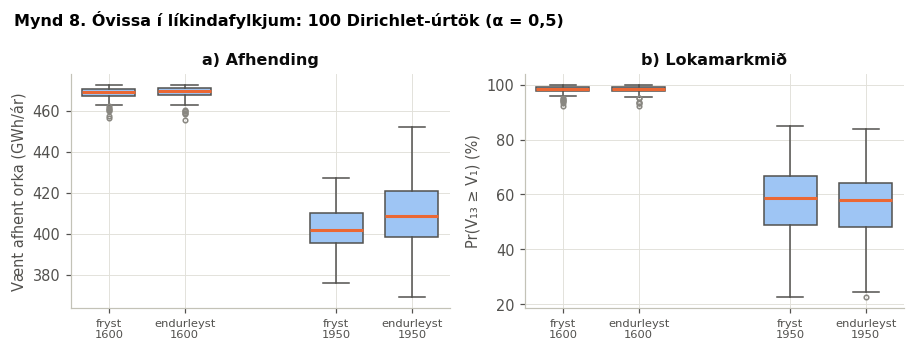

In [ ]:
rng = np.random.default_rng(2026)
alpha = 0.5                     # Jeffreys-forsenda á hverja röð: P_t(i,·) ~ Dirichlet(talningar + 0,5)
ovissa, kassar = {}, {}
for V1 in (1600, 1950):
    g = grunnur[V1]; st, base = g["st"], g["sdp"]
    fr, en, eftirsja = [], [], []
    for b in range(B_URTOK):
        Ps = np.array([[rng.dirichlet(il.talningar[t, i] + alpha) for i in range(3)] for t in range(12)])
        ils = cs.Innrennslislikan(il.mork, il.flokkar, il.talningar, Ps, il.Ibar, il.pi_des)
        a = cs.meta_net(base.stefna, ils, V1, base.Vnet)                   # fryst grunnstefna
        sd = cs.SDP(ils, st).leysa(); e = cs.meta_net(sd.stefna, ils, V1, sd.Vnet)   # endurleyst
        fr.append(a); en.append(e)
        obj = lambda z: z["E_afhent_GWh"] / cs.GWH_A_MWMAN - st.M * z["E_halli"] - st.mu * z["E_skortur_GWh"] / cs.GWH_A_MWMAN
        eftirsja.append(obj(e) - obj(a))
    bil = lambda L, k: [r(np.percentile([z[k] for z in L], q), 3) for q in (5, 50, 95)]
    ovissa[V1] = {"fryst": {k: bil(fr, k) for k in ("E_afhent_GWh", "P_V13_ge_V1", "E_halli", "areidanleiki")},
                  "endurleyst": {k: bil(en, k) for k in ("E_afhent_GWh", "P_V13_ge_V1", "E_halli", "areidanleiki")},
                  "eftirsja_MWman_5_50_95": [r(np.percentile(eftirsja, q), 2) for q in (5, 50, 95)]}
    kassar[V1] = (fr, en)
    # óháðir mánuðir: P = 1/3 alls staðar (engin samfella milli mánaða)
    ilu = cs.Innrennslislikan(il.mork, il.flokkar, il.talningar, np.full((12, 3, 3), 1 / 3), il.Ibar, il.pi_des)
    ovissa[V1]["oahadir_manudir_fryst"] = malikvardar(cs.meta_slodir(base.stefnufall(), ilu, V1), V1, "fryst", st.M)
    # ársinnrennsli keðjunnar á móti sögu
    Iann, p = g["Ip"].sum(1), g["rs"]["p"]
    ovissa[V1]["arsinnrennsli_kedja"] = {"medal": r(p @ Iann, 0), "sd": r(np.sqrt(p @ (Iann - p @ Iann) ** 2), 0),
                                         "min": r(Iann.min(), 0), "max": r(Iann.max(), 0), "P_lt_3534": r(p @ (Iann < 3534), 4)}
ovissa["saga_sd"] = r(I_thj.sum(axis=1).std(ddof=1), 0)
NID["ovissa"] = ovissa
print(json.dumps(ovissa, indent=1, ensure_ascii=False))

fig, axs = plt.subplots(1, 2, figsize=(8.4, 3.2))
kw = dict(widths=0.7, patch_artist=True, boxprops=dict(facecolor=BLAR_RAMPI[1], color=LIT["blek2"]),
          medianprops=dict(color=LIT["app"], lw=2), whiskerprops=dict(color=LIT["blek2"]),
          capprops=dict(color=LIT["blek2"]), flierprops=dict(ms=3, markeredgecolor=LIT["daufur"]))
for k, V1 in enumerate((1600, 1950)):
    fr, en = kassar[V1]
    axs[0].boxplot([[z["E_afhent_GWh"] for z in fr], [z["E_afhent_GWh"] for z in en]], positions=[3 * k, 3 * k + 1], **kw)
    axs[1].boxplot([[100 * z["P_V13_ge_V1"] for z in fr], [100 * z["P_V13_ge_V1"] for z in en]], positions=[3 * k, 3 * k + 1], **kw)
for ax in axs:
    ax.set_xticks([0, 1, 3, 4], ["fryst\n1600", "endurleyst\n1600", "fryst\n1950", "endurleyst\n1950"], fontsize=7.5)
axs[0].set_ylabel("Vænt afhent orka (GWh/ár)"); axs[0].set_title("a) Afhending")
axs[1].set_ylabel("Pr(V₁₃ ≥ V₁) (%)"); axs[1].set_title("b) Lokamarkmið")
fig.suptitle(f"Mynd 8. Óvissa í líkindafylkjum: {B_URTOK} Dirichlet-úrtök (α = 0,5)", fontsize=10.5, fontweight="bold", x=0.02, ha="left")
fig.tight_layout()
vista(fig, "mynd8_ovissa.png")

## 9. Álagspróf: hvenær bindur 95% krafan og hvenær stenst engin stefna?

,V1,rel_alltaf,rel_aldrei,stada,lam,rel_SDP,afhent_SDP,skortur_SDP_GWh,afhent_alltaf
0,900,0.4417,0.5974,engin_stefna,NaN,NaN,NaN,NaN,438.5
1,925,0.4609,0.6523,engin_stefna,NaN,NaN,NaN,NaN,440.5
2,950,0.5014,0.6770,engin_stefna,NaN,NaN,NaN,NaN,443.1
3,975,0.5274,0.7620,engin_stefna,NaN,NaN,NaN,NaN,445.7
4,1000,0.5974,0.8080,engin_stefna,NaN,NaN,NaN,NaN,448.7
5,1025,0.6516,0.8615,engin_stefna,NaN,NaN,NaN,NaN,453.4
6,1050,0.6920,0.8820,engin_stefna,NaN,NaN,NaN,NaN,456.0
7,1075,0.7112,0.9314,engin_stefna,NaN,NaN,NaN,NaN,459.4
8,1100,0.7867,0.9616,bindandi,0.688,0.9506,411.1,0.92,462.4
9,1125,0.8080,1.0000,obindandi,0.000,0.9808,426.8,0.00,464.9


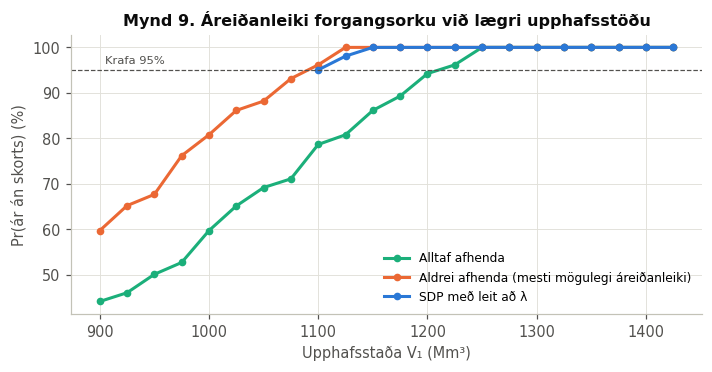

In [ ]:
alag = []
for V1 in range(900, 1426, 25):
    ra = cs.meta_slodir(cs.stefna_alltaf, il, V1); rn = cs.meta_slodir(cs.stefna_aldrei, il, V1)
    lam, sd, rr, stada = cs.finna_lam(il, cs.Stillingar(V1=V1))
    ok = stada != "engin_stefna"
    alag.append(dict(V1=V1, rel_alltaf=r(ra["areidanleiki"], 4), rel_aldrei=r(rn["areidanleiki"], 4), stada=stada,
                     lam=r(lam, 3) if ok else None, rel_SDP=r(rr["areidanleiki"], 4) if ok else None,
                     afhent_SDP=r(rr["E_afhent_GWh"], 1) if ok else None, skortur_SDP_GWh=r(rr["E_skortur_GWh"], 2) if ok else None,
                     afhent_alltaf=r(ra["E_afhent_GWh"], 1)))
alag = pd.DataFrame(alag); alag.to_csv(os.path.join(UT, "alagsprof.csv"), index=False)
display(alag); NID["alagsprof"] = alag.to_dict(orient="records")

fig, ax = plt.subplots(figsize=(7.4, 3.3))
ax.plot(alag.V1, 100 * alag.rel_alltaf, color=LIT["gr"], marker="o", ms=4, label="Alltaf afhenda")
ax.plot(alag.V1, 100 * alag.rel_aldrei, color=LIT["app"], marker="o", ms=4, label="Aldrei afhenda (mesti mögulegi áreiðanleiki)")
ok = alag.rel_SDP.notna()
ax.plot(alag.V1[ok], 100 * alag.rel_SDP[ok], color=LIT["blar"], marker="o", ms=4, label="SDP með leit að λ")
ax.axhline(95, color=LIT["blek2"], lw=0.8, ls="--"); ax.text(905, 96.5, "Krafa 95%", fontsize=7.5, color=LIT["blek2"])
ax.set_xlabel("Upphafsstaða V₁ (Mm³)"); ax.set_ylabel("Pr(ár án skorts) (%)")
ax.set_title("Mynd 9. Áreiðanleiki forgangsorku við lægri upphafsstöðu"); ax.legend(fontsize=8, loc="lower right")
vista(fig, "mynd9_alagsprof.png")

## 10. Yfirfall: hefði mátt selja meiri orku?

yfirfall_Mm3  afl_medal  klst_i_man  orka_yfirfalls_GWh  laust_afl_690_MW  laust_rennsli_m3s  yfirfall_m3s
ar   man                                                                                                            
2015 10           15.0      579.0         744                19.0             111.0               23.0           5.0
2016 8           153.0      569.0         744               204.0             121.0               25.0          57.0
     9           252.0      575.0         720               335.0             115.0               24.0          97.0
     10          260.0      561.0         744               346.0             129.0               27.0          97.0
     11            1.0      588.0         720                 1.0             102.0               21.0           0.0
2017 8            95.0      586.0         744               127.0             104.0               22.0          36.0
     9           467.0      604.0         720               621.0              86.0               18.0         180.0
     10          363.0      559.0         744               483.0             131.0               27.0         135.0
2018 8           319.0      555.0         744               425.0             135.0               28.0         119.0
     9            34.0      567.0         720                45.0             123.0               26.0          13.0
2019 8           245.0      526.0         744               326.0             164.0               34.0          92.0
     9           171.0      565.0         720               228.0             125.0               26.0          66.0
     10          101.0      538.0         744               134.0             152.0               32.0          38.0
2020 8            83.0      537.0         744               110.0             153.0               32.0          31.0
     9           108.0      537.0         720               144.0             153.0               32.0          42.0
2021 8           274.0      564.0         744               365.0             126.0               26.0         102.0
     9           533.0      558.0         720               709.0             132.0               28.0         206.0
2022 9           220.0      612.0         720               293.0              78.0               16.0          85.0
     10           43.0      575.0         744                58.0             115.0               24.0          16.0
2023 8           567.0      596.0         744               754.0              94.0               20.0         212.0
     9           259.0      608.0         720               345.0              82.0               17.0         100.0
2024 9             4.0      628.0         720                 5.0              62.0               13.0           2.0
2025 8           664.0      561.0         744               884.0             129.0               27.0         248.0
     9           615.0      560.0         720               818.0             130.0               27.0         237.0
     10           95.0      564.0         744               126.0             126.0               26.0          35.0

,1600,1800,1950
E_yfirfall_Mm3,475.0,654.0,799.0
orka_yfirfalls_GWh,632.0,871.0,1063.0
aukasala_575MW_GWh,48.0,60.0,68.0
aukasala_690MW_GWh,181.0,229.0,262.0


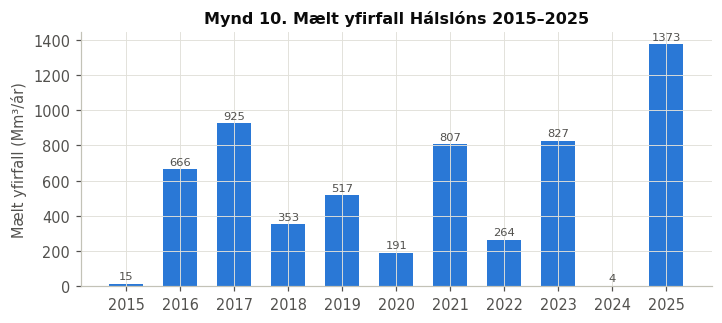

In [ ]:
# Mælingar: yfirfall og framleiðsla í mánuðum með yfirfalli
yf = t_man.loc[t_man["yfirfall_Mm3"] > 1, ["yfirfall_Mm3", "afl_medal", "klst_i_man"]].copy()
yf["orka_yfirfalls_GWh"] = yf["yfirfall_Mm3"] / cs.A_VATN * cs.GWH_A_MWMAN
yf["laust_afl_690_MW"] = 690 - yf["afl_medal"]
yf["laust_rennsli_m3s"] = (690 - yf["afl_medal"]) / cs.K
yf["yfirfall_m3s"] = yf["yfirfall_Mm3"] / (0.0036 * yf["klst_i_man"])
display(yf.round(0))
# Líkan: aukasala í mánuðum sem annars færu í yfirfall, upp að 575 MW (5 vélar) og 690 MW (6 vélar)
umfram = {}
for V1, g in grunnur.items():
    rs, p = g["rs"], g["rs"]["p"]; xs, Vs = rs["saga"]["x"], rs["saga"]["V"]
    Vb = np.concatenate([np.full((len(p), 1), float(V1)), Vs[:, :11]], axis=1)
    S = np.maximum(0, Vb + g["Ip"] - cs.A_VATN * (cs.FAST + xs) - cs.V_MAX)
    umfram[V1] = {"E_yfirfall_Mm3": r(p @ S.sum(1), 0), "orka_yfirfalls_GWh": r(p @ S.sum(1) / cs.A_VATN * cs.GWH_A_MWMAN, 0),
                  **{f"aukasala_{cap}MW_GWh": r(p @ np.minimum(S / cs.A_VATN, cap - (cs.FAST + xs)).sum(1) * cs.GWH_A_MWMAN, 0)
                     for cap in (575, 690)}}
display(pd.DataFrame(umfram))
NID["yfirfall"] = {"maelt": {f"{a}-{m}": row for (a, m), row in yf.round(1).to_dict(orient="index").items()}, "likan": umfram}

fig, ax = plt.subplots(figsize=(7.4, 3.0))
ys = t_man["yfirfall_Mm3"].groupby(level="ar").sum()
ax.bar(ys.index, ys.to_numpy(), color=LIT["blar"], width=0.62)
for a, v in ys.items():
    ax.text(a, v + 25, f"{v:.0f}", ha="center", fontsize=7.5, color=LIT["blek2"])
ax.set_xticks(ys.index); ax.set_ylabel("Mælt yfirfall (Mm³/ár)"); ax.set_title("Mynd 10. Mælt yfirfall Hálslóns 2015–2025")
vista(fig, "mynd10_yfirfall.png")

In [ ]:
with open(os.path.join(UT, "nidurstodur.json"), "w", encoding="utf-8") as f:
    json.dump(NID, f, ensure_ascii=False, indent=1, default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("Vistað:", sorted(os.listdir(UT)), sorted(os.listdir(MYND)))

Vistað: ['alagsprof.csv', 'naemni_M.csv', 'nidurstodur.json', 'prof2024_M10.csv', 'prof2024_M100.csv', 'prof2024_M2.csv', 'samanburdur_stefna.csv', 'soguleg_ar.csv'] ['mynd10_yfirfall.png', 'mynd1_innrennsli.png', 'mynd2_likindafylki.png', 'mynd3_stefnukort.png', 'mynd4_ferlar.png', 'mynd5_naemni_M.png', 'mynd6_2024.png', 'mynd7_klst2024.png', 'mynd8_ovissa.png', 'mynd9_alagsprof.png']


# Einstaklingshluti 2. Lengsta samfellda 54 MW afhendingin

**Guðný Lilja Alísa Gashi**

## Spurning og aðferð

Skoðum hversu marga mánuði í röð má lofa 54 MW viðbótarafli þegar 1.600 Mm³ eru í lóninu í ársbyrjun. Veljum upphafsmánuð og lengd tímabilsins fyrir fram. Krafan er að að minnsta kosti 95% líkur séu á að bæði 54 MW loforðið standist alla mánuði tímabilsins og 483 MW forgangsafl sé afhent allt árið.

Prófum fjóra upphafsmánuði. Janúar gefur kost á heilsársloforði, apríl er undir lok innrennslislítils tímabils, innrennslið eykst í júní og september kemur í kjölfar mestu sumarinnrennslismánaðanna. Tímabilið nær í mesta lagi til desember.

Notum grunnlíkanið, sem byggir á innrennslisgögnum frá 2015–2023. Höldum sömu refsingu ef vatnsstaðan fer undir 1.600 Mm³ í árslok. Utan lofaðs tímabils velur líkanið viðbótarafhendingu með hliðsjón af vatnsstöðu og innrennsli mánaðarins. Innan tímabilsins eru 54 MW afhent ef vatnið dugar. Annars fær forgangssamningurinn afl fyrst og viðbótarviðskiptavinurinn fær það sem eftir stendur.

Metum 95% kröfuna með því að leggja saman líkur þeirra innrennslisferla þar sem bæði afhendingarskilyrðin standast. Berum svo vænta afhenta viðbótarorku og vatnsstöðu í árslok saman við sveigjanlegu stefnu hópsins.

In [23]:
class BlokkarSDP(cs.SDP):
    """SDP hópsins með fastri afhendingu í fyrirfram völdum mánuðum."""

    def __init__(self, il, st, byrjun, lengd):
        super().__init__(il, st)

        self.blokk = range(byrjun - 1, byrjun - 1 + lengd)

    def akvarda(self, t, V, I, c, f, hluti=40000):
        if t not in self.blokk:
            return super().akvarda(t, V, I, c, f, hluti)
        W, F, D, xmax = cs.manudur(np.atleast_1d(V), I)
        x = xmax
        Vn, _ = cs.lok_manadar(W, F, x)
        fn = np.maximum(f, (D > 1e-9).astype(int))
        Q = x - self.st.mu * D + self._framhald(t, Vn, c, fn)
        return x, Q, F, D


def blokkar_likur(nidurstada, blokk):
    """Líkur á fullri afhendingu í blokkinni OG fullri forgangsorku allt árið."""
    full_blokk = (nidurstada["saga"]["x"][:, blokk] >= cs.AUKA - 1e-6).all(axis=1)
    forgangur = nidurstada["f"] == 0
    return float(nidurstada["p"] @ (full_blokk & forgangur))


In [24]:
V1_blokk = 1600
g_blokk = grunnur[V1_blokk]
grunnmat = g_blokk["rs"]
byrjanir = (1, 4, 6, 9)

alltaf_blokk = cs.meta_slodir(cs.stefna_alltaf, il, V1_blokk, geyma=True)
p_efri_notkun = blokkar_likur(alltaf_blokk, range(12))
assert np.isclose(alltaf_blokk["p"].sum(), 1)
assert np.isclose(p_efri_notkun, 1, atol=1e-12, rtol=0), (
    "Staðfestingin um 54 MW allt árið gildir ekki fyrir breytt innrennslislíkan."
)
print(f"54 MW í öllum mánuðum og full forgangsorka á {alltaf_blokk['fjoldi_ferla']:,} ferlum. "
      f"Sameiginlegar líkur: {p_efri_notkun:.1%}.")
print(f"Aukavatn fyrir 54 MW í einn mánuð: {cs.AUKA * cs.A_VATN:.2f} Mm³.")


def blokkar_row(heiti, mat, blokk=None):
    return {
        "Stefna": heiti,
        "L (mán.)": len(blokk) if blokk is not None else "—",
        "P(blokk og forgangur) (%)": (
            100 * blokkar_likur(mat, blokk) if blokk is not None else np.nan
        ),
        "P(forgangur) (%)": 100 * mat["areidanleiki"],
        "Afhent viðbót (GWh)": mat["E_afhent_GWh"],
        "Breyting í viðbót (GWh)": mat["E_afhent_GWh"] - grunnmat["E_afhent_GWh"],
        "Vænt lokastaða (Mm³)": mat["E_V13"],
        "P(V₁₃ ≥ 1600) (%)": 100 * (mat["p"] @ (mat["V13"] >= V1_blokk)),
        "Væntur lokahalli (Mm³)": mat["E_halli"],
        "Vænt yfirfall (Mm³)": mat["E_yfirfall"],
    }


blokkar_nidurstodur = {}
blokkar_radir = [blokkar_row("Sveigjanlegt SDP hópsins", grunnmat)]
for byrjun in byrjanir:

    lengd = 13 - byrjun
    sdp_blokk = BlokkarSDP(il, g_blokk["st"], byrjun, lengd).leysa()
    mat_blokk = cs.meta_slodir(sdp_blokk.stefnufall(), il, V1_blokk, geyma=True)
    assert blokkar_likur(mat_blokk, sdp_blokk.blokk) >= 0.95
    assert np.isclose(mat_blokk["p"].sum(), 1)
    blokkar_nidurstodur[byrjun] = sdp_blokk, mat_blokk
    blokkar_radir.append(blokkar_row(f"{cs.MAN[byrjun - 1].capitalize()}–des",
                                     mat_blokk, sdp_blokk.blokk))

blokkar_tafla = pd.DataFrame(blokkar_radir)
display(blokkar_tafla.round(3))


def lengsta_ahar(x):
    lengd = lengsta = 0
    for afl_i_manudi in x:
        lengd = lengd + 1 if afl_i_manudi >= cs.AUKA - 1e-6 else 0
        lengsta = max(lengsta, lengd)
    return lengsta


for ar in (2015, 2024):
    I_ar = I.loc[ar].to_numpy()
    c_ar = [cs.flokkur(gildi, t, il.mork) for t, gildi in enumerate(I_ar, 1)]
    runa = cs.keyra_ar(g_blokk["sdp"].stefnufall(), I_ar, c_ar, V1_blokk)
    print(f"{ar}, sveigjanleg stefna á mældu innrennsli: "
          f"lengsta 54 MW runa = {lengsta_ahar(runa['x'])} mánuðir.")


54 MW í öllum mánuðum og full forgangsorka á 66,528 ferlum. Sameiginlegar líkur: 100.0%.
Aukavatn fyrir 54 MW í einn mánuð: 29.62 Mm³.


,Stefna,L (mán.),P(blokk og forgangur) (%),P(forgangur) (%),Afhent viðbót (GWh),Breyting í viðbót (GWh),Vænt lokastaða (Mm³),P(V₁₃ ≥ 1600) (%),Væntur lokahalli (Mm³),Vænt yfirfall (Mm³)
0,Sveigjanlegt SDP hópsins,—,NaN,100.0,469.10,0.000,1896.972,97.339,1.144,475.030
1,Jan–des,12,100.0,100.0,473.04,3.940,1894.052,96.553,3.720,474.990
2,Apr–des,9,100.0,100.0,473.04,3.940,1894.052,96.553,3.720,474.990
3,Jún–des,7,100.0,100.0,473.04,3.940,1894.052,96.553,3.720,474.990
4,Sep–des,4,100.0,100.0,472.73,3.631,1894.212,96.579,3.573,475.063


2015, sveigjanleg stefna á mældu innrennsli: lengsta 54 MW runa = 7 mánuðir.
2024, sveigjanleg stefna á mældu innrennsli: lengsta 54 MW runa = 12 mánuðir.


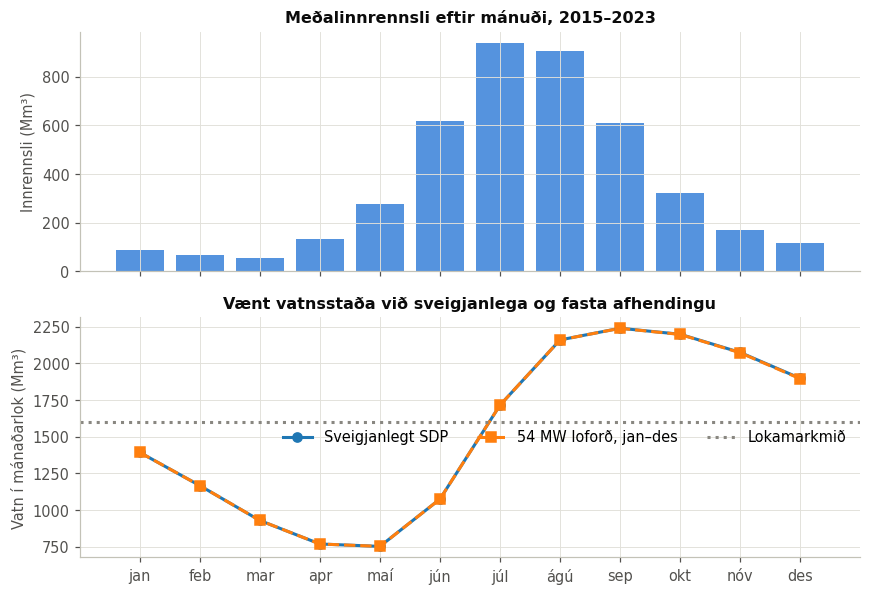

In [25]:
fig, (ax_in, ax_v) = plt.subplots(2, 1, figsize=(8, 5.5), sharex=True)
ax_in.bar(man, I_thj.mean().to_numpy(), color=LIT["blar"], alpha=.8)
ax_in.set(ylabel="Innrennsli (Mm³)", title="Meðalinnrennsli eftir mánuði, 2015–2023")
ax_v.plot(man, grunnmat["man"]["EV"], marker="o", label="Sveigjanlegt SDP")
ax_v.plot(man, blokkar_nidurstodur[1][1]["man"]["EV"], marker="s", linestyle="--",
          label="54 MW loforð, jan–des")
ax_v.axhline(V1_blokk, color=LIT["daufur"], linestyle=":", label="Lokamarkmið")
ax_v.set(ylabel="Vatn í mánaðarlok (Mm³)", xticks=man, xticklabels=cs.MAN,
         title="Vænt vatnsstaða við sveigjanlega og fasta afhendingu")
ax_v.legend(ncol=3)
fig.tight_layout()
vista(fig, "einstaklingshluti_2_vatnsstada.png")


### Niðurstöður

Lengsta blokkin er 12 mánuðir, frá janúar til desember. Full 54 MW viðbótarafhending og full forgangsorka allt árið nást saman á öllum 66.528 innrennslisferlum með jákvæðar líkur í metna líkaninu. Sameiginlegar líkur eru því 100%. Útreikningurinn vegur hvern feril með líkum hans. Þessar líkur eru niðurstaða innan metna líkansins.

| Stefna | Lengsta blokk (mán.) | Sameiginlegar líkur | Vænt viðbótarorka (GWh) | Vænt vatn í árslok (Mm³) | Líkur á ≥ 1.600 Mm³ í árslok |
|---|---:|---:|---:|---:|---:|
| Sveigjanlegt SDP hópsins | — | — | 469,10 | 1.896,97 | 97,34% |
| Janúar–desember | 12 | 100% | 473,04 | 1.894,05 | 96,55% |
| Apríl–desember | 9 | 100% | 473,04 | 1.894,05 | 96,55% |
| Júní–desember | 7 | 100% | 473,04 | 1.894,05 | 96,55% |
| September–desember | 4 | 100% | 472,73 | 1.894,21 | 96,58% |

*Í töflunni er vatnsmarkmiðið metið beint við 1.600 Mm³. Í aðaltöflu hópsins er 1 Mm³ vikmörk vegna ákvörðunarnets. Forgangsorkan næst allt árið á öllum ferlum við allar stefnurnar í töflunni.*

Prófum fyrst að afhenda eins mikið og vatnið leyfir í hverjum mánuði. Sú stefna nær 537 MW á öllum innrennslisferlum líkansins. Minni viðbótarafhending getur aðeins haldið vatnsstöðunni óbreyttri eða hækkað hana á sama ferli. Því er 95% krafan óbindandi og tímabil frá öllum fjórum upphafsmánuðunum geta náð til desember.

### Túlkun og takmarkanir

Janúar gengur sem upphafsmánuður því 1.600 Mm³ duga til að komast í gegnum innrennslislítinn vetur og vor. Með heilsársloforði fer vatnsstaðan í mánaðarlok lægst í um 435 Mm³ á öllum ferlunum, um 335 Mm³ yfir friðaða forðanum. Innrennsli eykst í júní og er mest í júlí og ágúst. Heildarafhendingin, 537 MW, rúmast innan 575 MW hámarksafls með einni vél í viðhaldi.

Full 54 MW viðbótarafhending notar 29,62 Mm³ á mánuði. Heilsársloforðið skilar að væntingu 3,94 GWh meiri viðbótarorku en sveigjanlega stefnan. Á móti lækkar vænt vatnsstaða í árslok um 2,92 Mm³ og væntur halli miðað við lokamarkmiðið hækkar úr 1,14 í 3,72 Mm³. Sveigjanlega stefnan getur sparað vatn fyrir næsta ár með því að skerða viðbótarafhendingu undir lok árs. Þegar verðmæti þess vatns er tekið með fær heilsársloforðið lægra markgildi.

Lofað tímabil er ákveðið fyrir fram. Í sögulegri endurspilun er lengsta samfellda runan fundin eftir á og getur byrjað í ólíkum mánuðum milli ára. Með sveigjanlegu stefnunni og sömu upphafsstöðu var lengsta 54 MW runan sjö mánuðir árið 2015 og tólf árið 2024. Árið 2024 var utan þjálfunargagnanna, en ein slík keyrsla nægir ekki til að staðfesta 95% líkur fyrir framtíðarsamning.

Líkanið byggir á níu þjálfunarárum, þremur innrennslisflokkum á mánuði og einu sameinuðu vatnsbóli. Flokkameðaltölin geta falið öfgagildi og gögnin ná aðeins yfir takmarkaðan fjölda þurrkatímabila. Niðurstaðan um 12 mánuði gildir því við forsendur líkansins. Raunverulegt afhendingarloforð krefst einnig mats á sveiflum innan mánaðar, vélarbilunum og flutningstakmörkunum.
